# **Importing the Libraries**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer  
from sklearn.model_selection import train_test_split 
from sklearn.pipeline import Pipeline           
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 📦 Core Data Manipulation Libraries

* **`numpy`**: **Handles complex math and fast numerical calculations** by organizing numbers into structured grids or lists called arrays.
* **`pandas`**: **Organizes and manages data tables** (called DataFrames) just like an automated Excel spreadsheet inside your code.
* **`matplotlib.pyplot`**: **Creates baseline charts and custom graphs** such as line plots, scatter plots, and histograms to view your data visually.
* **`seaborn`**: **Builds highly polished, modern data visualizations** on top of matplotlib, making it easy to create beautiful heatmaps and comparison charts.
* **`math`**: **Accesses standard mathematical functions** built directly into Python, like calculating square roots, rounding numbers, or handling exponents.

---

# ⚙️ Machine Learning & Data Processing Tools (`scikit-learn`)

* **`ColumnTransformer`**: **Applies different cleaning steps to specific columns simultaneously**, allowing you to treat numeric columns and text columns differently at the exact same time.
* **`SimpleImputer`**: **Fills in missing data blanks automatically**, replacing empty cells with values like the average (mean) so your machine learning model does not crash.
* **`train_test_split`**: **Splits your dataset into separate piles**—typically using 80% of the data to teach the model (train) and reserving 20% to grade its final accuracy (test).
* **`Pipeline`**: **Chains all data processing steps into a single workflow**, ensuring that your raw data flows cleanly from cleaning to prediction without manual errors.
* **`OneHotEncoder`**: **Converts text categories into binary 0 and 1 columns**, turning qualitative labels like phone colors or brands into numeric matrices a model can compute.
* **`StandardScaler`**: **Rescales all numbers to the exact same size scale**, preventing massive numbers (like a 5,000mAh battery) from overwhelming smaller numbers (like 8GB of RAM).


### Loading the dataset in notebook

In [3]:
df = pd.read_csv(r"C:\Users\Shilpi\OneDrive\Desktop\Mobile Phone data.csv")

In [3]:
df

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,"11,999"
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,"5,649"
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"
...,...,...,...,...,...,...,...,...,...,...,...,...
536,637,SAMSUNG Galaxy S23 5G,Cream,256,8,3900,50MP,12MP,0,15.49,Qualcomm Snapdragon 8 Gen 2,"79,999"
537,638,LAVA Z21,Cyan,32,2,3100,5MP,2MP,0,12.70,Octa Core,"5,998"
538,639,Tecno Spark 8T,Turquoise Cyan,64,4,5000,50MP,8MP,0,16.76,MediaTek Helio G35,"9,990"
539,641,SAMSUNG Galaxy A54 5G,Awesome Lime,128,8,5000,50MP,32MP,0,16.26,"Exynos 1380, Octa Core","38,999"


In [4]:
df.drop("Unnamed: 0", axis = 1, inplace = True)

The command `df.drop("Unnamed: 0", axis=1, inplace=True)` **permanently removes the column named `"Unnamed: 0"` from DataFrame**. 

In [5]:
### Column Name Standardization
### Some column names in the raw dataset were incorrect or contained trailing underscores. We clean them up by explicitly renaming them:
df = df.rename(columns={"Prize": "Price", "Battery_": "Battery", "Processor_" : "Processor"})

In [6]:
# checking the shape of dataset.
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 541
Columns: 11


In [7]:
# checking first 5 rows
df.head()

,Model,Colour,Memory,RAM,Battery,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor,Price
0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,"11,999"
3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,"5,649"
4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"


In [8]:
# checking last 5 rows
df.tail()

,Model,Colour,Memory,RAM,Battery,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor,Price
536,SAMSUNG Galaxy S23 5G,Cream,256,8,3900,50MP,12MP,0,15.49,Qualcomm Snapdragon 8 Gen 2,"79,999"
537,LAVA Z21,Cyan,32,2,3100,5MP,2MP,0,12.70,Octa Core,"5,998"
538,Tecno Spark 8T,Turquoise Cyan,64,4,5000,50MP,8MP,0,16.76,MediaTek Helio G35,"9,990"
539,SAMSUNG Galaxy A54 5G,Awesome Lime,128,8,5000,50MP,32MP,0,16.26,"Exynos 1380, Octa Core","38,999"
540,OPPO A77,Sky Blue,128,4,5000,50MP,8MP,0,16.66,Mediatek Helio G35,"15,999"


In [9]:
# checking any 10 random rows
df.sample(10)

,Model,Colour,Memory,RAM,Battery,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor,Price
305,MOTOROLA Edge 30 Fusion,Cosmic grey,128,8,4400,50MP,32MP,0,16.64,Qualcomm Snapdragon 888 +,"34,999"
2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,"11,999"
297,realme C33,Sandy Gold,64,4,5000,50MP,5MP,0,16.51,Unisoc T612,"9,999"
408,POCO F5 5G,Electric Blue,256,4,5000,64MP,16MP,0,16.94,Qualcomm Snapdragon 7+ Gen 2 (4nm),"32,999"
9,Infinix HOT 30i,Mirror Black,64,4,5000,50MP,5MP,1,16.76,G37,"7,999"
295,realme 8,Punk Black,128,4,5000,64MP,16MP,0,16.26,MediaTek Helio G95,"13,499"
159,REDMI K50i 5G,Stealth Black,256,8,5080,64MP,16MP,0,16.76,Dimensity 8100,"23,999"
126,Infinix NOTE 12i,Alpine White,64,4,5000,50MP,8MP,0,17.02,Mediatek Helio G85,"9,999"
406,Infinix Note 12 5G,Snowfall,64,6,5000,50MP,16MP,1,17.02,Mediatek Dimensity 810 5G,"14,999"
213,vivo T1 44W,Midnight Galaxy,128,4,5000,50MP,16MP,0,16.36,Qualcomm Snapdragon 680,"14,499"


In [10]:
# Checking the columns in the dataset
df.columns

Index(['Model', 'Colour', 'Memory', 'RAM', 'Battery', 'Rear Camera',
       'Front Camera', 'AI Lens', 'Mobile Height', 'Processor', 'Price'],
      dtype='object')

In [11]:
# Checking the null value and datatypes of DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Model          541 non-null    object 
 1   Colour         541 non-null    object 
 2   Memory         541 non-null    int64  
 3   RAM            541 non-null    int64  
 4   Battery        541 non-null    int64  
 5   Rear Camera    541 non-null    object 
 6   Front Camera   541 non-null    object 
 7   AI Lens        541 non-null    int64  
 8   Mobile Height  541 non-null    float64
 9   Processor      541 non-null    object 
 10  Price          541 non-null    object 
dtypes: float64(1), int64(4), object(6)
memory usage: 46.6+ KB


This shows that we no null values in our dataframe and also showing the types of data like - object, int and float.

In [76]:
# this also clarifies in a more clear way that there is no missing or null values in our dataframe
df.isna().sum()

Model            0
Colour           0
Memory           0
RAM              0
Battery          0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor        0
Price            0
dtype: int64

- The dataset is completely clean with no missing data, empty spaces, or weird values. Every column is fully filled out, so we can jump straight into analyzing it without fixing anything first!

### 💰 Data Type Correction: Converting Price to Integer
We identified that the **Price** column is currently stored as an object (text) data type instead of a number. To perform mathematical operations, calculations, and statistical analysis, we must clean this column and convert it into a proper integer format.

### 📷 Extracting Camera Megapixels
We extract the numeric megapixel values from the raw **Rear Camera** and **Front Camera** text columns. Using regular expressions (regex), this code isolates the numbers (e.g., transforming `"50 MP Triple Camera"` into `50.0`) and converts them into decimal format so we can use them in mathematical analysis and graphs.


In [8]:
# found that price column is an object dtype so needs to change in int
df['Price'] = df['Price'].astype(str).str.replace(',', '')

# Now converted it to an integer
df['Price'] = df['Price'].astype(int)

# Extract camera megapixels
df["Rear Camera MP"] = pd.to_numeric(
    df["Rear Camera"].astype(str).str.extract(r"([\d.]+)")[0],
    errors="coerce"
)

df["Front Camera MP"] = pd.to_numeric(
    df["Front Camera"].astype(str).str.extract(r"([\d.]+)")[0],
    errors="coerce"
)

In [9]:
# Checking Unique Values in Categorical columns
for i in df.select_dtypes(include='object').columns:
    print(f"=== Unique Values in Column: {i} ===")
    print(df[i].unique()[:20])  # Shows the first 20 unique items
    print("-" * 30)

=== Unique Values in Column: Model ===
['Infinix SMART 7' 'MOTOROLA G32' 'POCO C50' 'Infinix HOT 30i' 'REDMI 10'
 'SAMSUNG Galaxy F13' 'SAMSUNG Galaxy F04' 'POCO C51' 'MOTOROLA e13'
 'vivo T2x 5G' 'Infinix Smart 7 HD' 'REDMI A1+' 'POCO C55' 'MOTOROLA g13'
 'POCO M4 5G' 'MOTOROLA e32' 'vivo T2 5G' 'MOTOROLA G62 5G' 'POCO M5'
 'realme C33 2023']
------------------------------
=== Unique Values in Column: Colour ===
['Night Black' 'Azure Blue' 'Mineral Gray' 'Royal Blue' 'Marigold'
 'Glacier Blue' 'Mirror Black' 'Diamond White' 'Shadow Black'
 'Emerald Green' 'Waterfall Blue' 'Opal Green' 'Power Black'
 'Country Green' 'Cosmic Black' 'Aurora Gold' 'Marine Blue'
 'Glimmer Black' 'Green Apple' 'Black']
------------------------------
=== Unique Values in Column: Rear Camera ===
['13MP' '50MP' '8MP' '40MP' '32MP' '48MP' '64MP' '108MP' '0MP' '2MP'
 '12MP' '200MP' '5MP' '16MP']
------------------------------
=== Unique Values in Column: Front Camera ===
['5MP' '16MP' '8MP' '13MP' '0MP' '32MP' '

In [79]:
# checking the stastical numbers
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Memory,541.0,110.550832,60.600694,16.0,64.00,128.00,128.00,256.00
RAM,541.0,5.397412,1.984923,2.0,4.00,6.00,8.00,8.00
Battery,541.0,4871.587800,780.148862,800.0,5000.00,5000.00,5000.00,7000.00
AI Lens,541.0,0.062847,0.242911,0.0,0.00,0.00,0.00,1.00
Mobile Height,541.0,16.431201,2.523553,4.5,16.51,16.71,16.94,41.94
Price,541.0,16228.375231,10793.588322,920.0,9290.00,13499.00,19280.00,80999.00
Rear Camera MP,541.0,46.110906,31.260416,0.0,13.00,50.00,50.00,200.00
Front Camera MP,541.0,11.992606,9.053746,0.0,5.00,8.00,16.00,60.00


In [80]:
# List the names of all numeric columns
numeric_cols = df.select_dtypes(include=['number']).columns
print("Numerical Columns:", list(numeric_cols))
df[numeric_cols].head()

Numerical Columns: ['Memory', 'RAM', 'Battery', 'AI Lens', 'Mobile Height', 'Price', 'Rear Camera MP', 'Front Camera MP']


,Memory,RAM,Battery,AI Lens,Mobile Height,Price,Rear Camera MP,Front Camera MP
0,64,4,6000,1,16.76,7299,13,5
1,64,4,6000,1,16.76,7299,13,5
2,128,8,5000,0,16.64,11999,50,16
3,32,2,5000,0,16.56,5649,8,5
4,128,8,5000,1,16.76,8999,50,5


In [81]:
# list the names of all categorical columns
cat_cols = df.select_dtypes(include=["object", "category"]).columns
print("Categorical columns:", list(cat_cols))
df[cat_cols].head()

Categorical columns: ['Model', 'Colour', 'Rear Camera', 'Front Camera', 'Processor']


,Model,Colour,Rear Camera,Front Camera,Processor
0,Infinix SMART 7,Night Black,13MP,5MP,Unisoc Spreadtrum SC9863A1
1,Infinix SMART 7,Azure Blue,13MP,5MP,Unisoc Spreadtrum SC9863A1
2,MOTOROLA G32,Mineral Gray,50MP,16MP,Qualcomm Snapdragon 680
3,POCO C50,Royal Blue,8MP,5MP,Mediatek Helio A22
4,Infinix HOT 30i,Marigold,50MP,5MP,G37


### 📊 Setting Up Automated Data Visualization
This code imports the **AutoViz** library and prepares the visualizer engine. Instead of writing dozens of lines of chart code manually, this will automatically generate customized plots for our dataset.

In [10]:
from autoviz.AutoViz_Class import AutoViz_Class

AV = AutoViz_Class()

Imported v0.1.905. Please call AutoViz in this sequence:
    AV = AutoViz_Class()
    %matplotlib inline
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)


### 🚀 Automated Exploratory Data Analysis (EDA)
Executing the automated data visualization pipeline via `AV.AutoViz`. This function profiles the structure of the dataset and renders optimized distributions, pairwise relationships, and statistical charts embedded directly within the notebook interface.

Shape of your Data Set loaded: (541, 13)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  1
    Number of Integer-Categorical Columns =  6
    Number of String-Categorical Columns =  2
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  0
    Number of Numeric-Boolean Columns =  1
    Number of Discrete String Columns =  3
    Number of NLP String Columns =  0
    Number of Date Time Columns =  0
    Number of ID Columns =  0
    Number of Columns to Delete =  0
    13 Predictors classified...
        No variables removed since no ID or low-information variables found in data set
To fix these data quality issues in the dataset, import FixDQ from autoviz...
There are 10 dup

,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
Model,object,0.000000,35,,,Possible high cardinality column with 187 unique values: Use hash encoding or text embedding to reduce dimension.
Colour,object,0.000000,51,,,Possible high cardinality column with 275 unique values: Use hash encoding or text embedding to reduce dimension.
Memory,int64,0.000000,0,16.000000,256.000000,Column has 55 outliers greater than upper bound (224.00) or lower than lower bound(-32.00). Cap them or remove them.
RAM,int64,0.000000,0,2.000000,8.000000,No issue
Battery,int64,0.000000,6,800.000000,7000.000000,Column has 148 outliers greater than upper bound (5000.00) or lower than lower bound(5000.00). Cap them or remove them.
Rear Camera,object,0.000000,2,,,"4 rare categories: ['5MP', '40MP', '32MP', '16MP']. Group them into a single category or drop the categories."
Front Camera,object,0.000000,2,,,"5 rare categories: ['60MP', '2MP', '10MP', '44MP', '20MP']. Group them into a single category or drop the categories."
AI Lens,int64,0.000000,0,0.000000,1.000000,No issue
Mobile Height,float64,0.000000,NA,4.500000,41.940000,Column has 32 outliers greater than upper bound (17.59) or lower than lower bound(15.87). Cap them or remove them.
Processor,object,0.000000,23,,,Possible high cardinality column with 123 unique values: Use hash encoding or text embedding to reduce dimension.


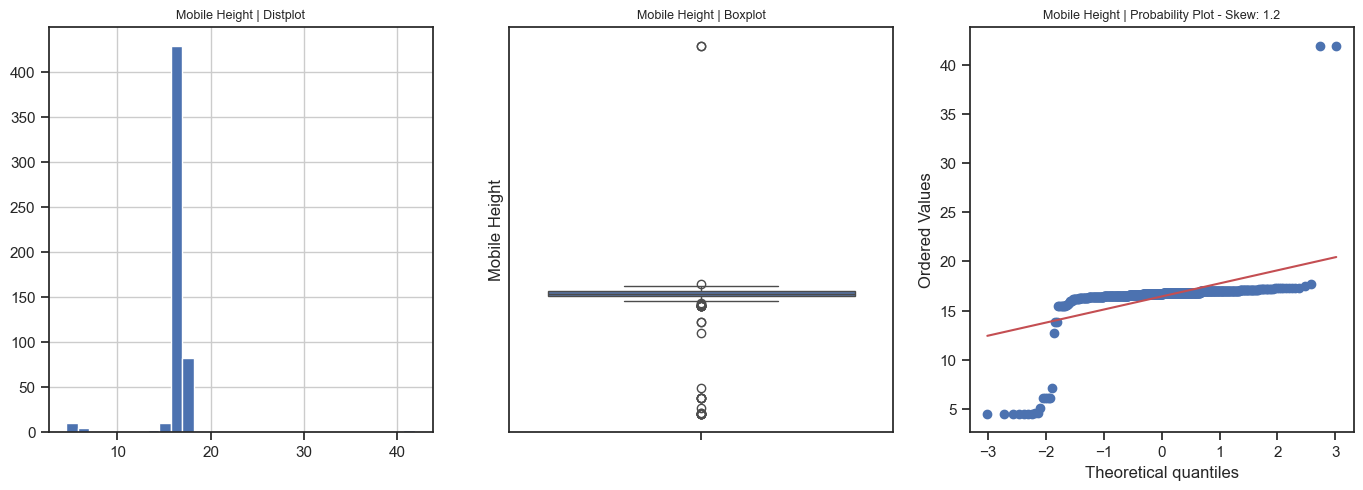

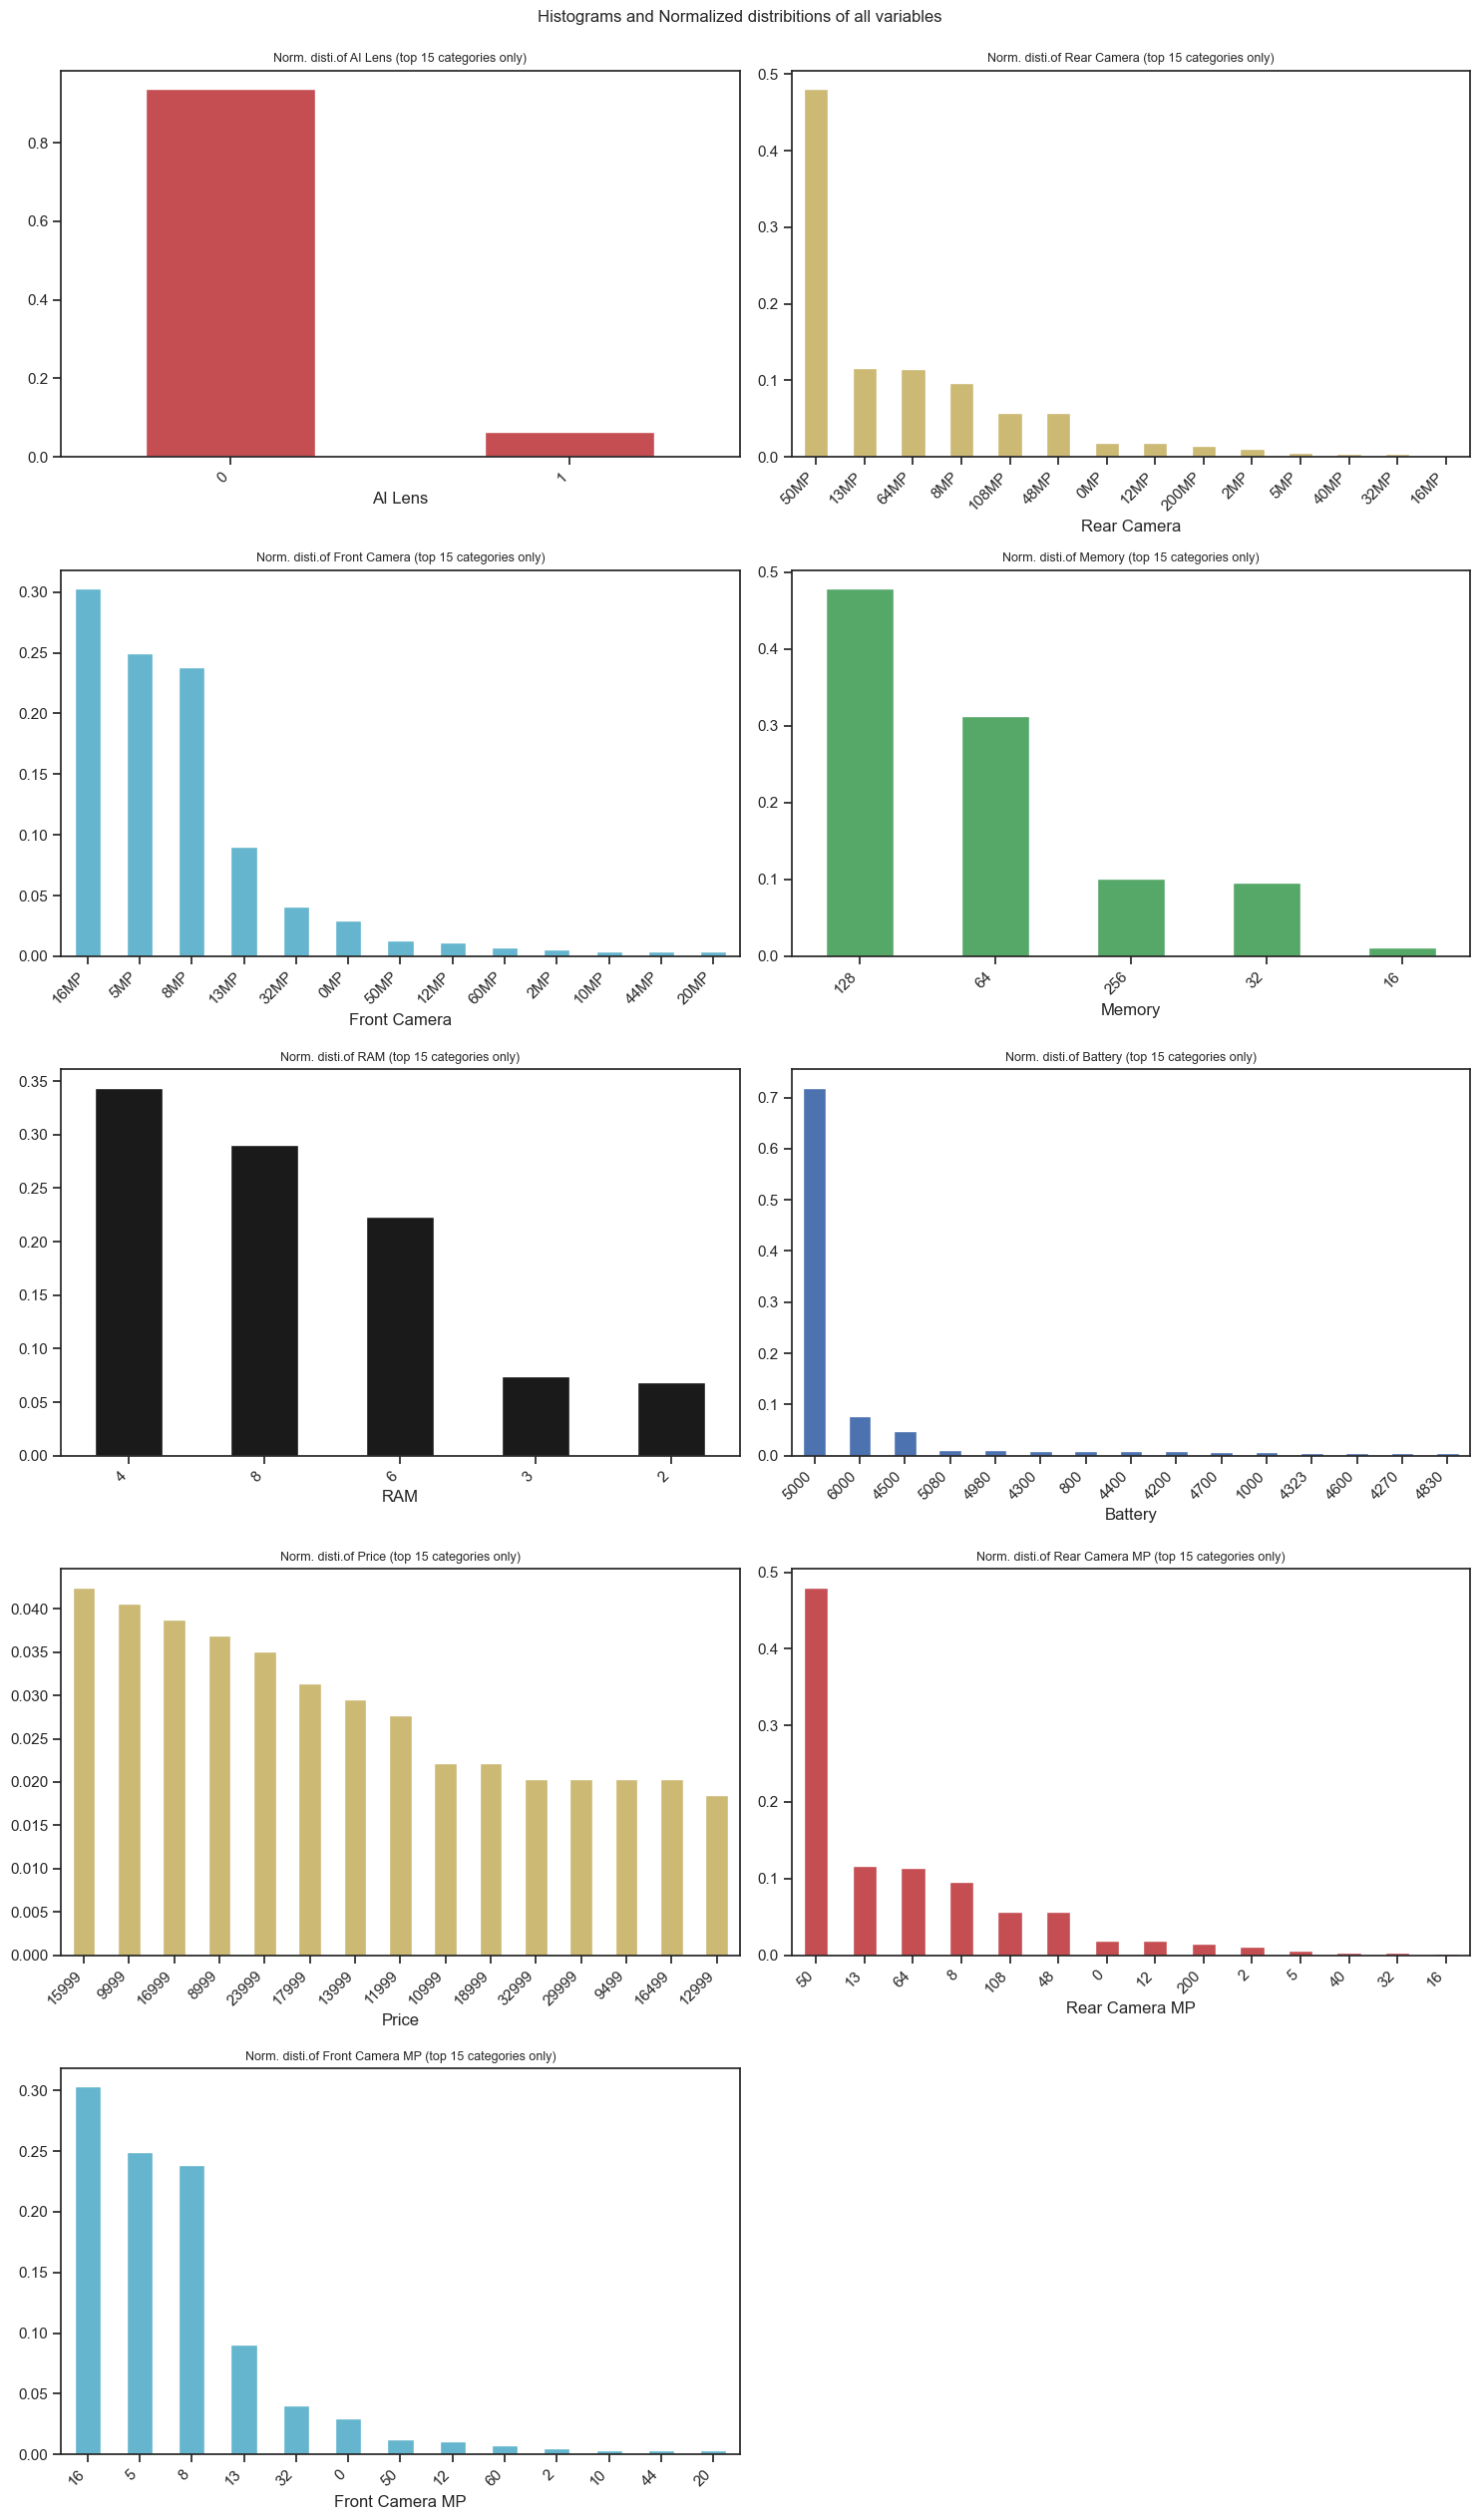

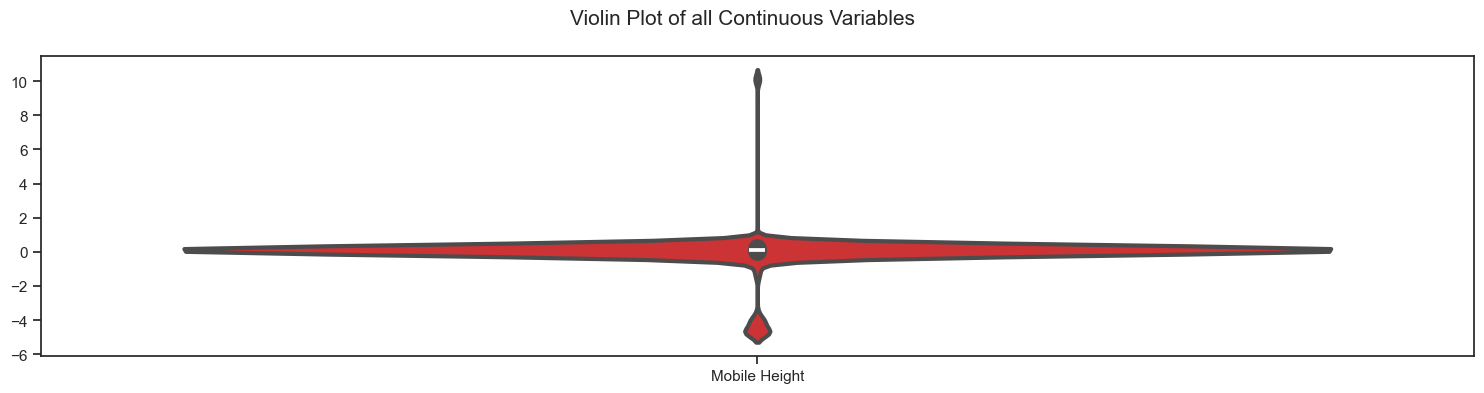

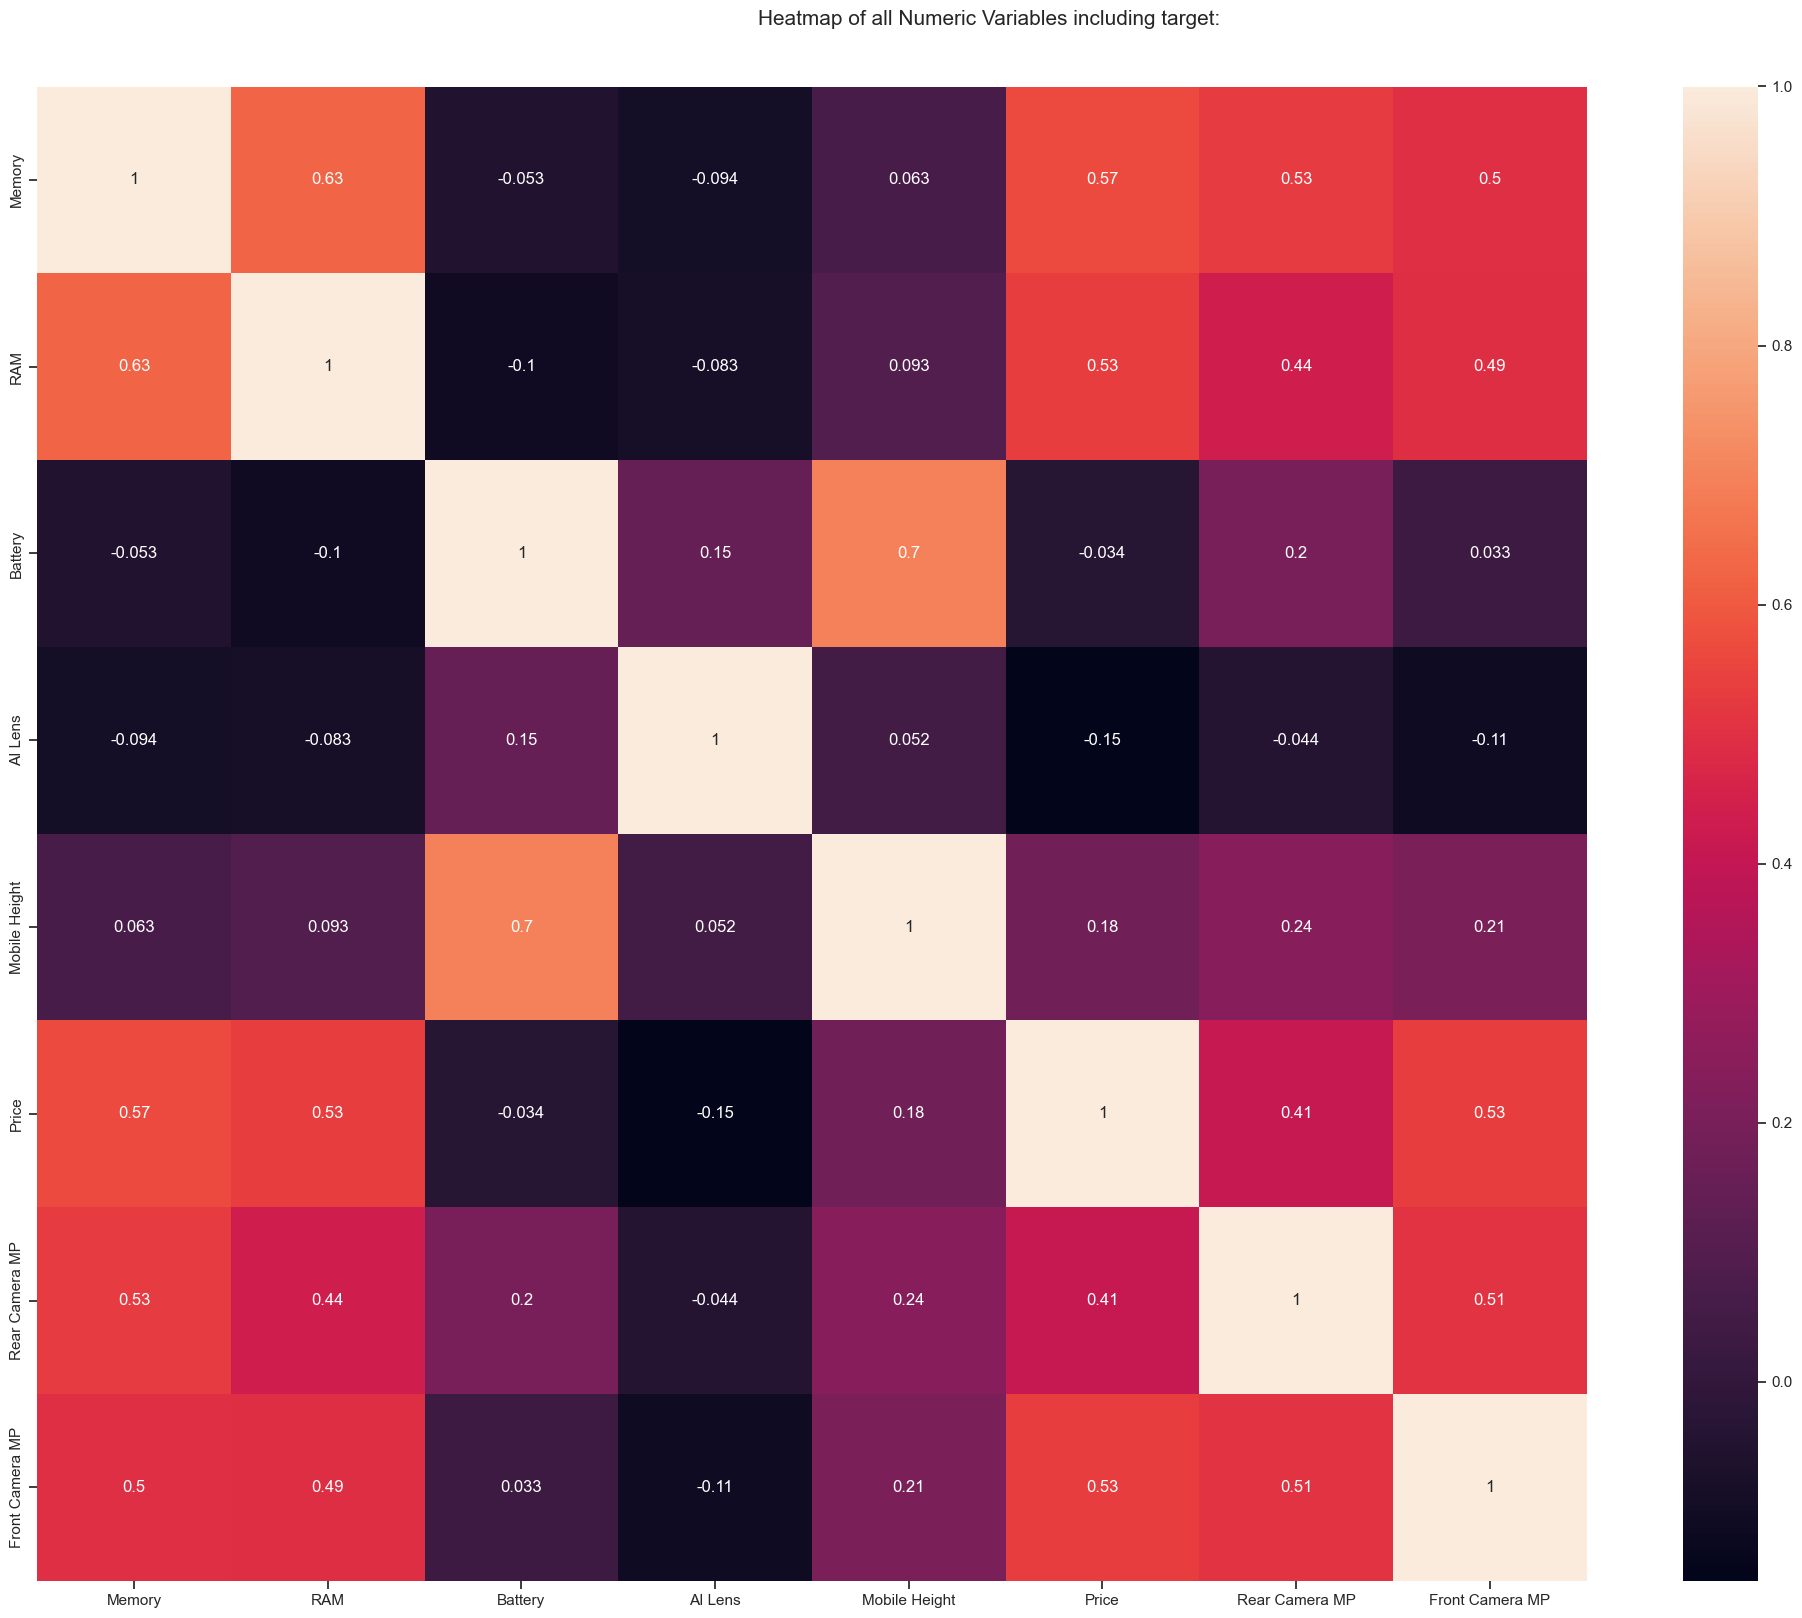

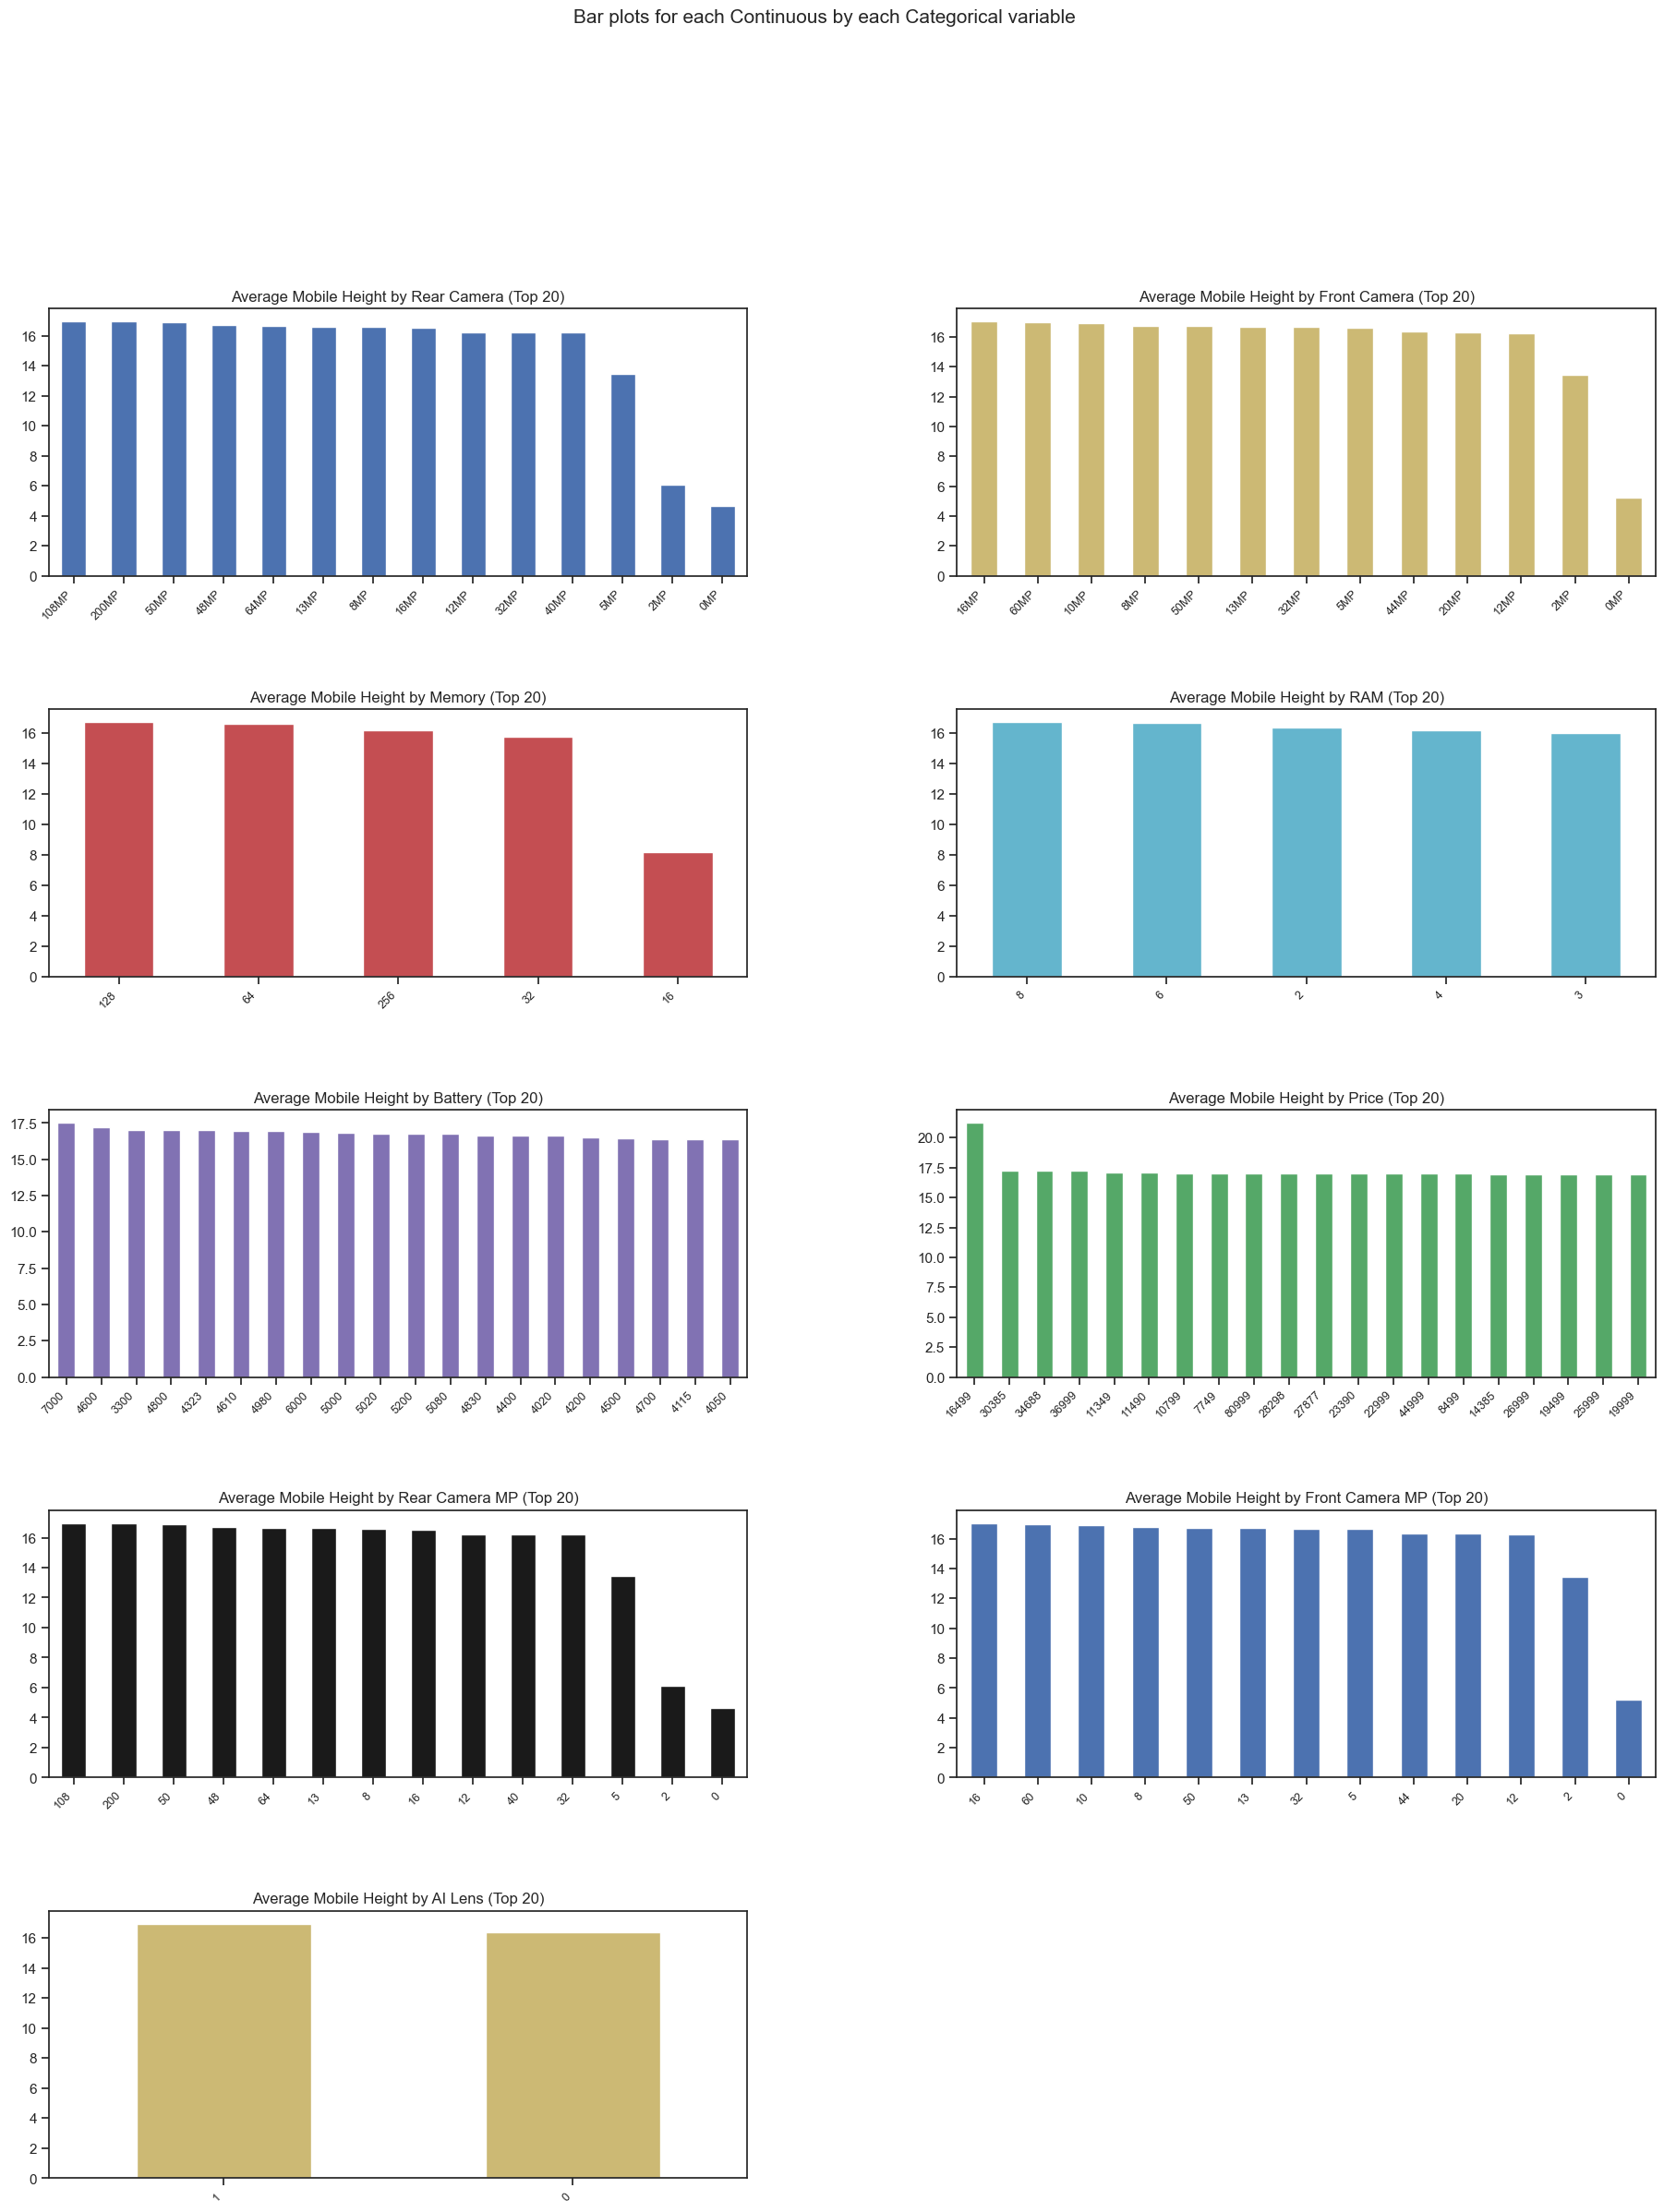

[nltk_data] Downloading collection 'popular'
[nltk_data]    | 
[nltk_data]    | Downloading package cmudict to
[nltk_data]    |     C:\Users\Shilpi\AppData\Roaming\nltk_data...
[nltk_data]    |   Package cmudict is already up-to-date!
[nltk_data]    | Downloading package gazetteers to
[nltk_data]    |     C:\Users\Shilpi\AppData\Roaming\nltk_data...
[nltk_data]    |   Package gazetteers is already up-to-date!
[nltk_data]    | Downloading package genesis to
[nltk_data]    |     C:\Users\Shilpi\AppData\Roaming\nltk_data...
[nltk_data]    |   Package genesis is already up-to-date!
[nltk_data]    | Downloading package gutenberg to
[nltk_data]    |     C:\Users\Shilpi\AppData\Roaming\nltk_data...
[nltk_data]    |   Package gutenberg is already up-to-date!
[nltk_data]    | Downloading package inaugural to
[nltk_data]    |     C:\Users\Shilpi\AppData\Roaming\nltk_data...
[nltk_data]    |   Package inaugural is already up-to-date!
[nltk_data]    | Downloading package movie_reviews to
[nltk_dat

Could not draw wordcloud plot for Model. 
Looks like you are missing some required data for this feature.

To download the necessary data, simply run

    python -m textblob.download_corpora

or use the NLTK downloader to download the missing data: http://nltk.org/data.html
If this doesn't fix the problem, file an issue at https://github.com/sloria/TextBlob/issues.

Could not draw wordcloud plot for Colour. 
Looks like you are missing some required data for this feature.

To download the necessary data, simply run

    python -m textblob.download_corpora

or use the NLTK downloader to download the missing data: http://nltk.org/data.html
If this doesn't fix the problem, file an issue at https://github.com/sloria/TextBlob/issues.

Could not draw wordcloud plot for Processor. 
Looks like you are missing some required data for this feature.

To download the necessary data, simply run

    python -m textblob.download_corpora

or use the NLTK downloader to download the missing data: http://n

In [11]:
# 1. Keeps plots embedded inside the notebook cell
%matplotlib inline

# 2. Corrected parameter names and visibility flags
dft = AV.AutoViz(
    filename="",
    sep=",",
    depVar="",
    dfte=df,          # FIXED: Properly passed df to the dfte parameter
    header=0,
    verbose=1,        # FIXED: Changed from 0 to 1 so the charts actually display
    lowess=False,
    chart_format="svg",
    max_rows_analyzed=150000,
    max_cols_analyzed=37
)

### 🚨 Statistical Outlier Detection (IQR Method)
We apply the **Interquartile Range (IQR)** method to detect statistical outliers across our numerical features. By calculating the middle 50% of the data (`IQR = Q3 - Q1`), we establish lower and upper thresholds (`± 1.5 * IQR`). Any data point falling outside these boundaries is flagged as an outlier, allowing us to see which features (like extreme Prices or massive Batteries) contain anomalous values.

,Feature,Lower Bound,Upper Bound,Outlier Count
1,RAM,-2.000,14.000,0
7,Front Camera MP,-11.500,32.500,13
5,Price,-5695.000,34265.000,25
4,Mobile Height,15.865,17.585,33
3,AI Lens,0.000,0.000,34
6,Rear Camera MP,-42.500,105.500,39
0,Memory,-32.000,224.000,55
2,Battery,5000.000,5000.000,152


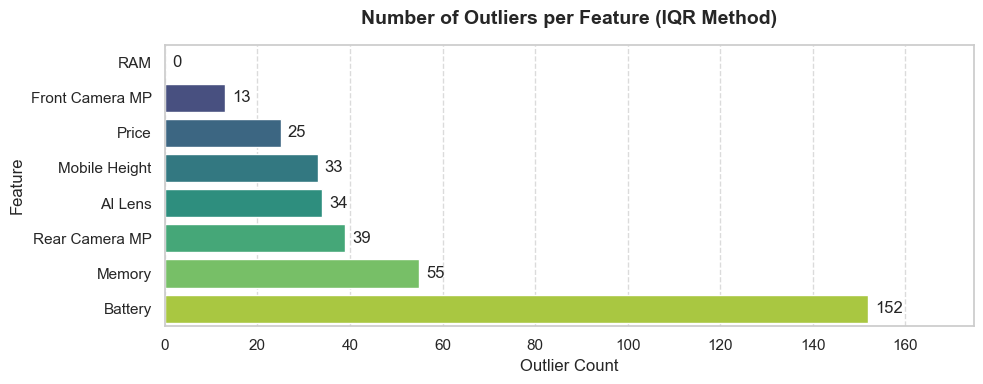

In [68]:
# IQR-based outlier counts
num_cols = df.select_dtypes(include='number')

outlier_summary = []

for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append([col, lower, upper, int(count)])

# Createed the DataFrame
outlier_df = pd.DataFrame(
    outlier_summary,
    columns=["Feature", "Lower Bound", "Upper Bound", "Outlier Count"]
).sort_values(by="Outlier Count", ascending=True)

# Display the sorted summary table
display(outlier_df)

# Plot the graph
plt.figure(figsize=(10, max(4, len(outlier_df) * 0.4)))
ax = sns.barplot(
    data=outlier_df, 
    x="Outlier Count", 
    y="Feature", 
    palette="viridis", 
    hue="Feature", 
    legend=False
)

# Loop through all containers
for container in ax.containers:
    ax.bar_label(container, padding=5, fontweight='normal')

# Format the plot
plt.title("Number of Outliers per Feature (IQR Method)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Outlier Count", fontsize=12)
plt.ylabel("Feature", fontsize=12)

plt.xlim(0, outlier_df["Outlier Count"].max() * 1.15 if outlier_df["Outlier Count"].max() > 0 else 10)

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Why we do not automatically delete every outlier

An outlier is not automatically an error. A premium smartphone can legitimately cost much more than the majority of phones.

Instead of blindly deleting observations, this project:
1. identifies unusual values,
2. keeps legitimate market variation,
3. uses robust tree-based models,
4. and reports the presence of unusual values.

This is safer for a real pricing problem.

### 📦 Visualizing Outliers via Boxplots
We generate side-by-side **boxplots** for all numerical variables in the dataset. This visualization complements our statistical IQR table by providing a clear, graphical view of the distribution, the median, the interquartile range (the box), and any extreme values (dots extending past the whiskers) that represent potential outliers.


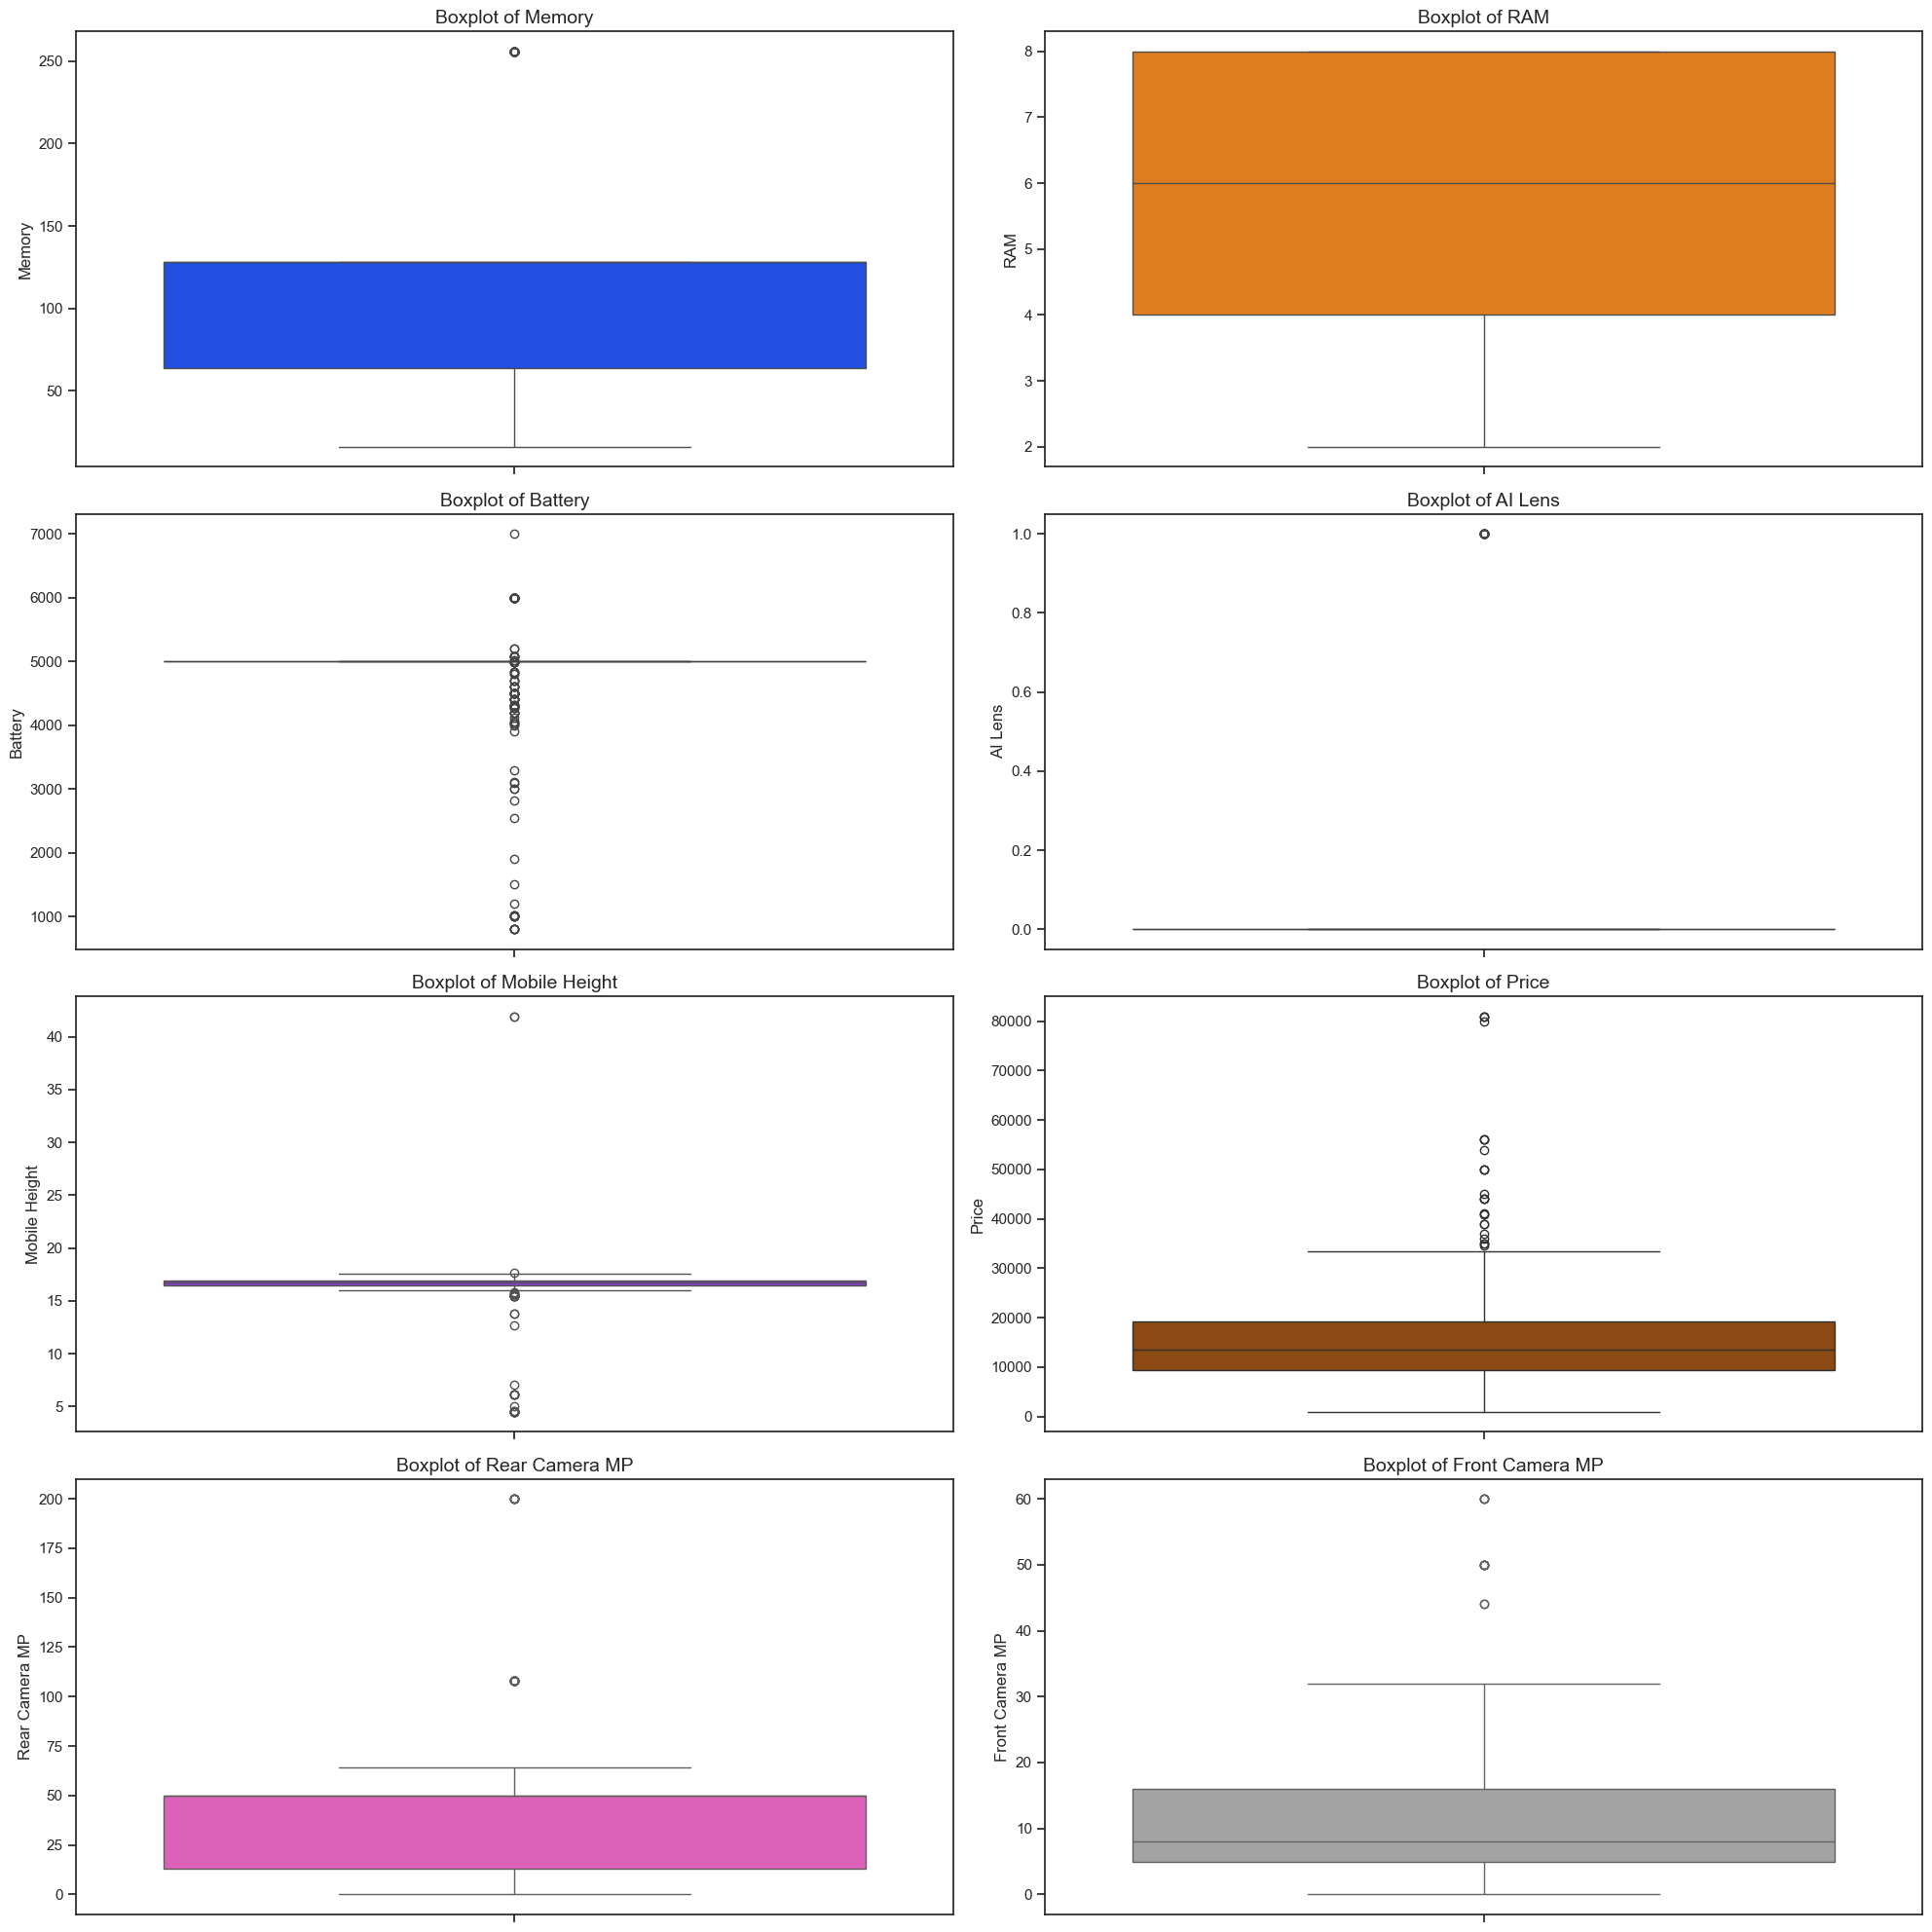

In [16]:
# 1. Identify numeric columns
numeric_cols = df.select_dtypes(include=["number"]).columns

# 2. Calculate dynamic grid dimensions (2 columns wide)
num_rows = (len(numeric_cols) + 1) // 2
fig, axes = plt.subplots(ncols=2, nrows=num_rows, figsize=(20, num_rows * 5))

# Flatten axes array for easy 1D looping
axes_flat = axes.flatten()

# 3. Plot the boxplots for each numeric column
colors = sns.color_palette("bright", len(numeric_cols))

for i, col in enumerate(numeric_cols):
    ax = axes_flat[i]
    sns.boxplot(data=df, y=col, ax=ax, color=colors[i])
    ax.set_title(f"Boxplot of {col}", fontsize=14)
    ax.set_xlabel("")  # Cleans up the x-axis label

# 4. this will remove any unused empty subplots
for j in range(len(numeric_cols), len(axes_flat)):
    fig.delaxes(axes_flat[j])

plt.tight_layout()
plt.show()

### 📊 Examining Feature Distributions and Skewness
We plot modern **histograms combined with Kernel Density Estimation (KDE) curves** to observe data symmetry. 
* **Statistical Indicators:** The dashed red line outlines the **Mean**, the solid green line tracks the **Median**, and the blue dash-dotted lines outline one **Standard Deviation** from the average.
* **Skewness Analysis:** If the skew value is **positive**, the distribution stretches far out to the right (tailing higher values). If it's **negative**, it tilts heavily to the left. A value close to **0** outlines a perfectly balanced, bell-shaped distribution.


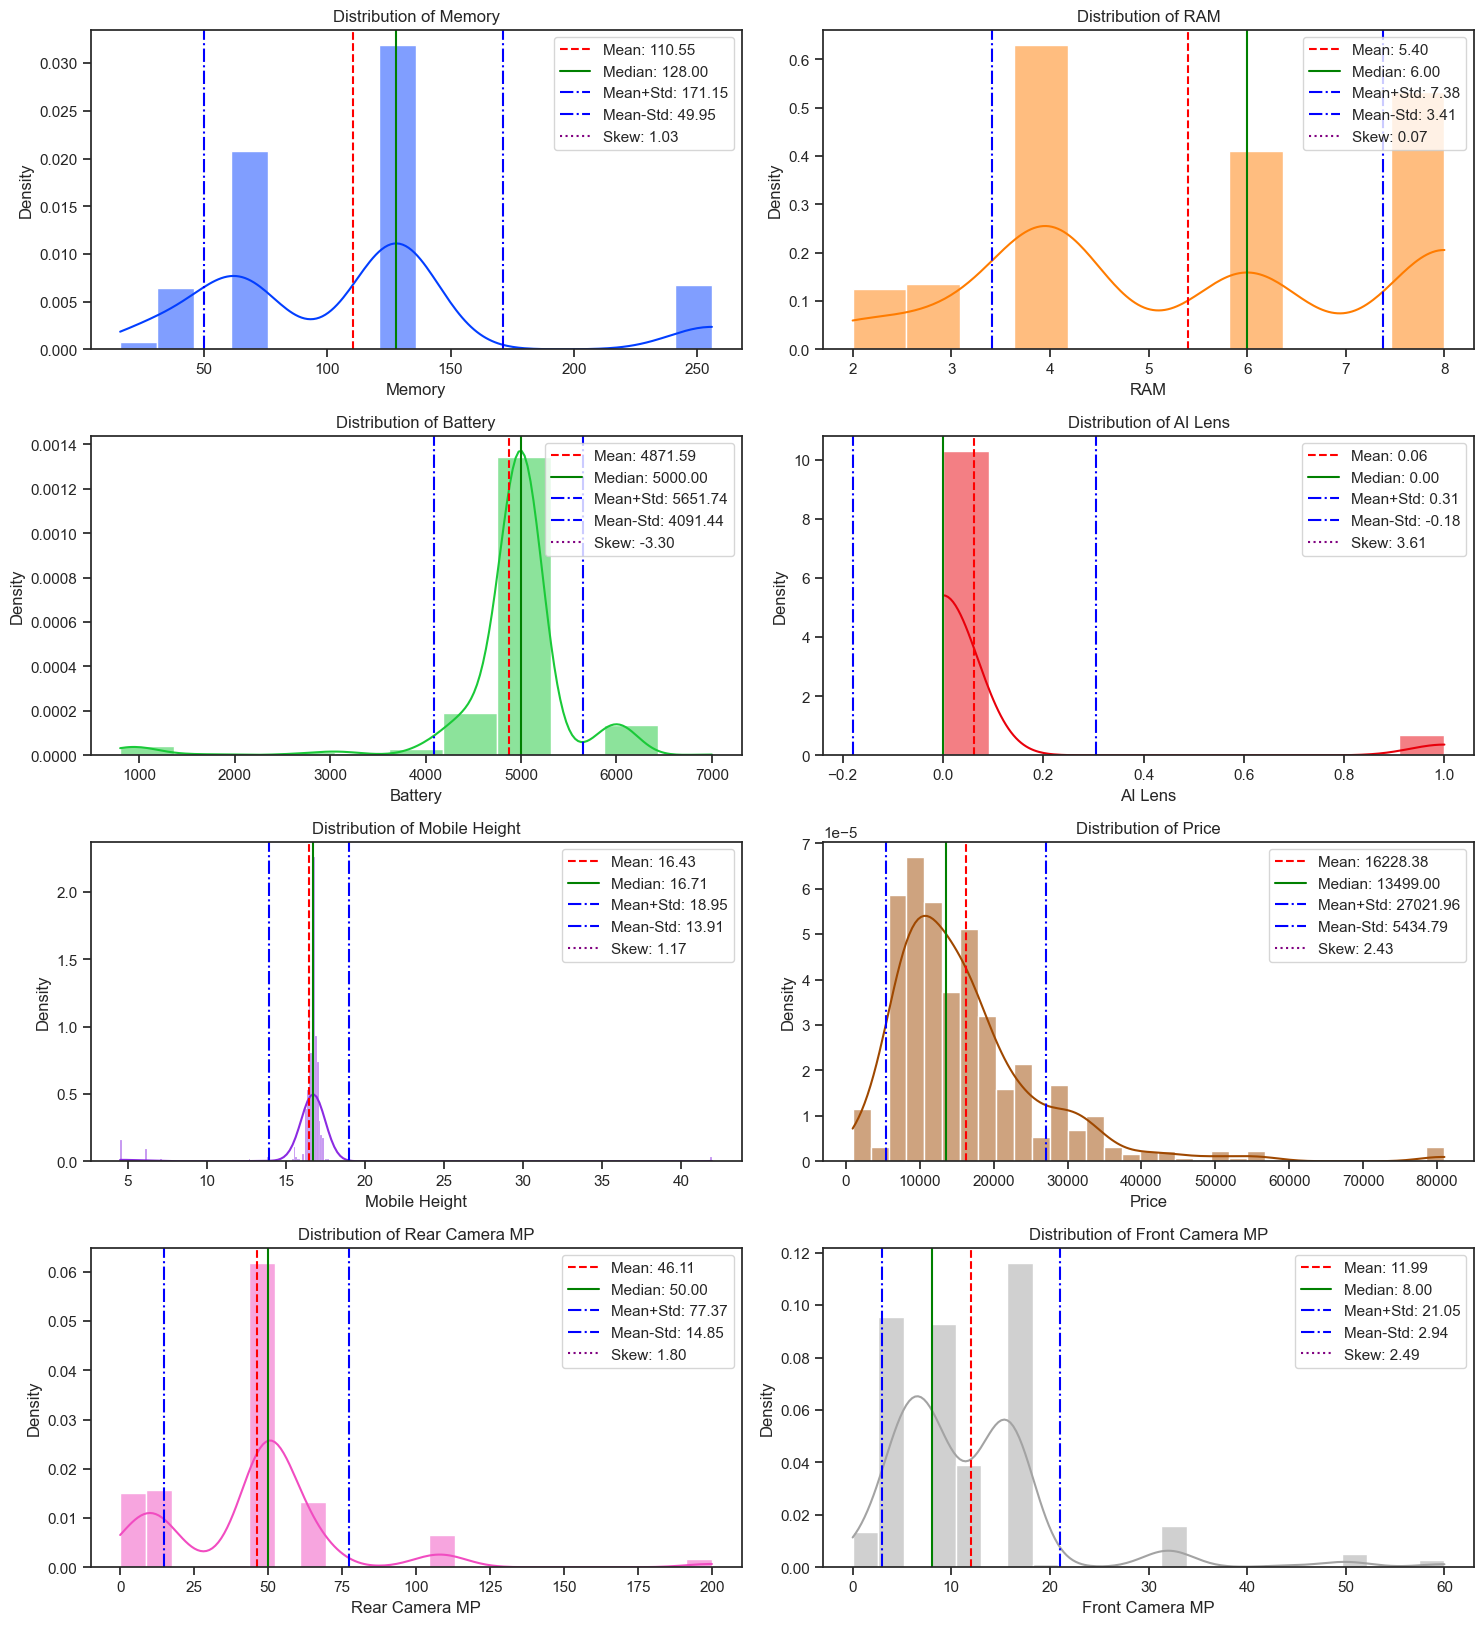

In [17]:
from matplotlib.lines import Line2D

numeric_cols = df.select_dtypes(include=['number']).columns
plt.figure(figsize=(15, 20))

for i, col in enumerate(numeric_cols):
    ax = plt.subplot(len(numeric_cols) // 2 + 1, 2, i + 1)
    
    sns.histplot(df[col], 
                 color=sns.color_palette("bright", len(numeric_cols))[i], 
                 kde=True,
                 stat="density",
                 ax=ax)
    ax.set_title(f'Distribution of {col}')
    
    mean = df[col].mean()
    std_dev = df[col].std()
    median = df[col].median()
    skewness = df[col].skew()
    
    ax.axvline(mean, color='red', linestyle='--', label=f'Mean: {mean:.2f}')
    ax.axvline(median, color='green', linestyle='-', label=f'Median: {median:.2f}')
    ax.axvline(mean + std_dev, color='blue', linestyle='-.', label=f'Mean+Std: {mean + std_dev:.2f}')
    ax.axvline(mean - std_dev, color='blue', linestyle='-.', label=f'Mean-Std: {mean - std_dev:.2f}')
    
    skew_line = Line2D([], [], color='purple', linestyle=':', label=f'Skew: {skewness:.2f}')
    handles, labels = ax.get_legend_handles_labels()
    handles.append(skew_line)
    labels.append(f'Skew: {skewness:.2f}')
    
    ax.legend(handles=handles, loc='upper right')

plt.tight_layout()
plt.show()

No outlier treatment will be done because Mobile prices can be very high. Such high prices are considered normal and not true outliers.

# EDA

### 💰 Deep Dive: Mobile Price Distribution
We isolate and plot a high-resolution histogram of the **Price** feature using 30 bins and a smooth KDE line. This visualization allows us to see the exact price brackets where the majority of smartphones cluster (e.g., budget vs. premium sectors) and highlights how long the luxury "high-end" price tail stretches to the right.

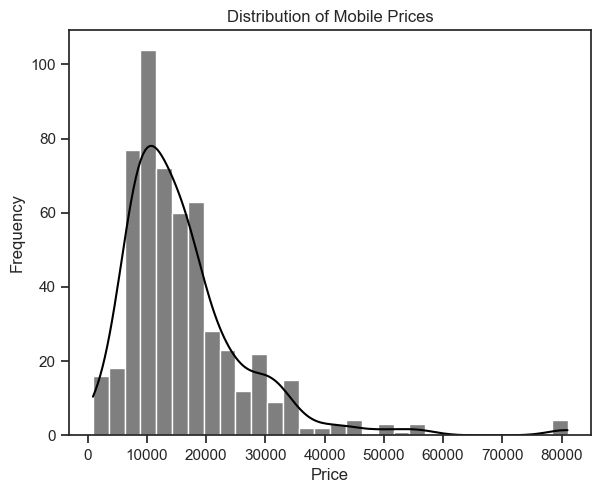

In [23]:
plt.figure(figsize=(6, 5))
sns.histplot(df["Price"], kde=True, bins=30, color="black")
plt.title("Distribution of Mobile Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

### 📈 Statistical Insights: Mobile Price Distribution

* **Dominant Mid-Range Pricing:** The majority of smartphones are clustered between **10,000 and 15,000 units**. This bracket represents the highest peak on our chart, indicating that manufacturer supply and consumer demand are heavily concentrated around mid-range devices.

* **Right-Skewed Distribution:** The data displays a prominent right-skewed tail. While the bulk of inventory populates the entry-to-mid price tiers, a long, thin tail extends toward higher-priced models. These ultra-premium options are significantly fewer in number.

* **Secondary Peak at Premium Levels:** A minor, secondary concentration emerges around the **35,000 price range**. This represents a distinct market segment dedicated to premium/flagship devices, positioned right before luxury pricing sets in.

* **Market Emphasis on Affordability:** The sharp drop-off in model frequencies immediately following the 15,000 unit threshold underscores that value-oriented pricing dominates this dataset, leaving top-tier flagships as a specialized minority.


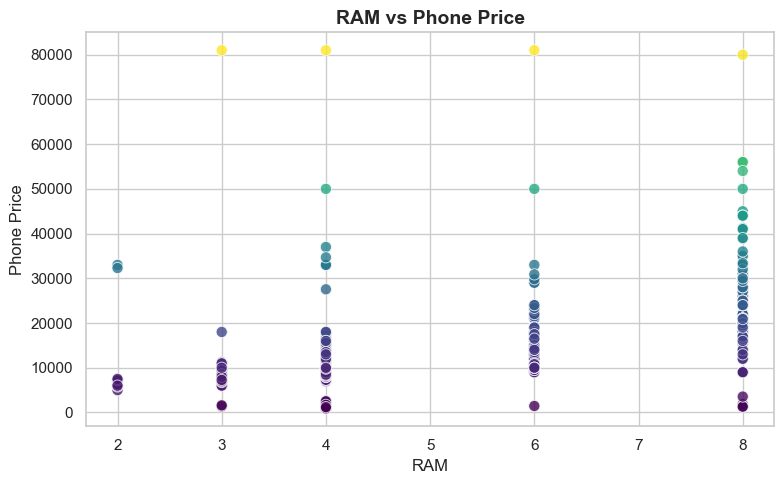

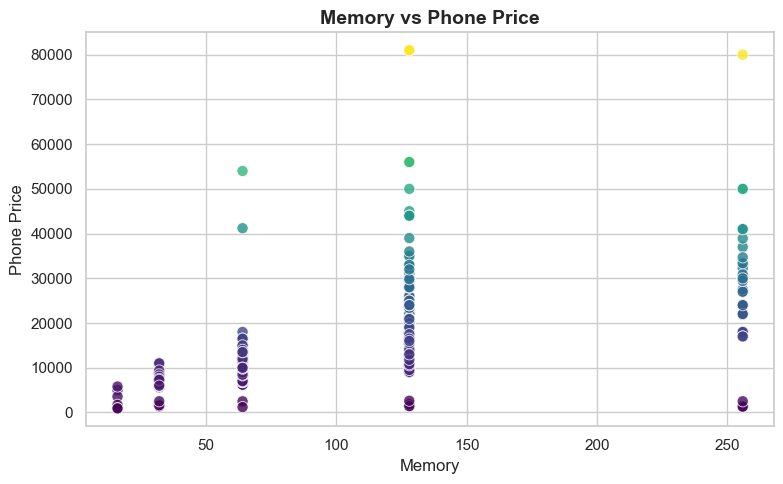

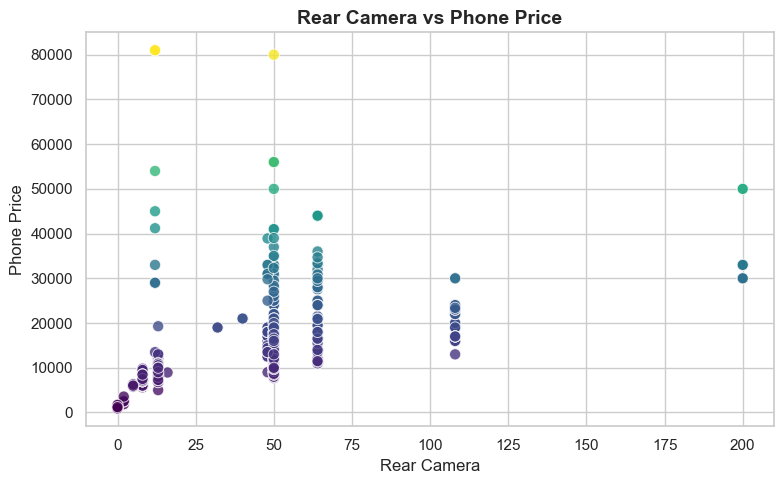

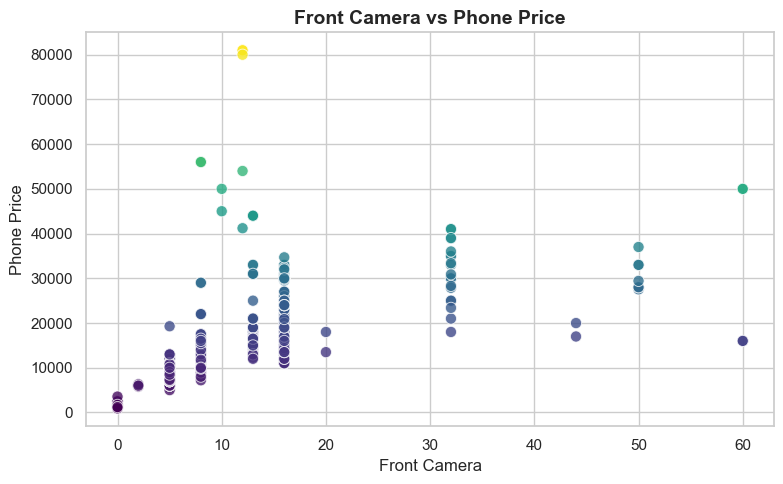

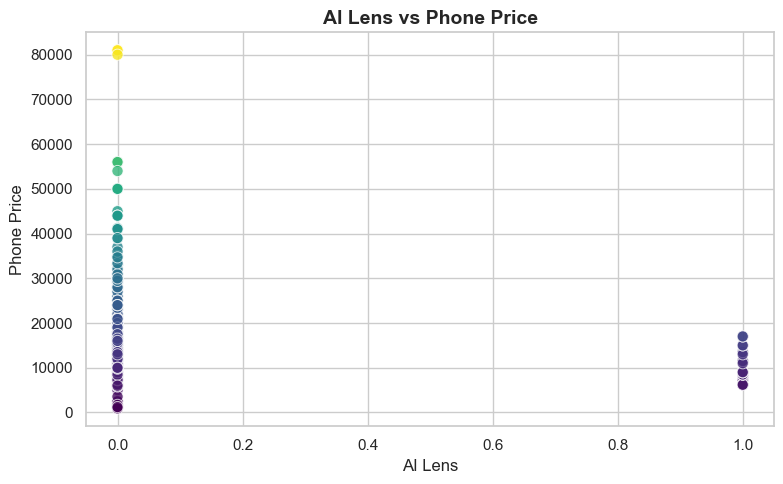

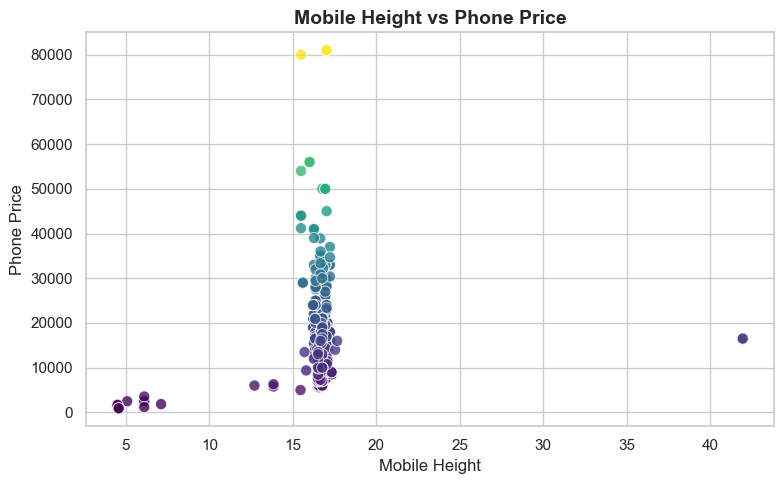

In [24]:
sns.set_theme(style="whitegrid", palette="bright")

df_fe = df.copy()
df_fe.columns = df_fe.columns.astype(str).str.strip()
target = "Price"
features = [
    "RAM",
    "Memory",
    "Battery_",
    "Rear Camera",
    "Front Camera",
    "AI Lens",
    "Mobile Height"
]

# Keep only columns that exist
features = [col for col in features if col in df_fe.columns]

# Convert values to numeric
for col in features + [target]:
    df_fe[col] = pd.to_numeric(
        df_fe[col].astype(str).str.replace(",", "", regex=False)
        .str.extract(r"([-+]?\d*\.?\d+)", expand=False),
        errors="coerce"
    )

# Create one colourful scatter plot for each feature
for col in features:
    plot_data = df_fe[[col, target]].dropna()

    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=plot_data,
        x=col,
        y=target,
        hue=target,
        palette="viridis",
        legend=False,
        alpha=0.8,
        s=65
    )

    plt.title(f"{col} vs Phone Price", fontsize=14, fontweight="bold")
    plt.xlabel(col)
    plt.ylabel("Phone Price")
    plt.tight_layout()
    plt.show()


## Insights from Feature vs. Mobile Phone Price Analysis
### 1. RAM vs. Price
RAM is an important feature to investigate when predicting mobile phone prices. Phones with higher RAM may tend to have higher prices because they can support more demanding applications and multitasking. The scatter plot helps identify whether this relationship is visible in our dataset.

### 2. Internal Memory vs. Price
Internal memory represents the phone's storage capacity. A pattern of increasing prices with higher memory would suggest a positive relationship between storage and price. However, phones with the same storage capacity may have different prices because of other specifications.

### 3. Battery Capacity vs. Price
The scatter plot helps us understand whether battery capacity is associated with phone prices. If the points are widely scattered, battery capacity alone may not explain price differences. Other factors, such as RAM, storage, and camera specifications, may also contribute.

### 4. Rear Camera vs. Price
This visualisation examines the relationship between rear-camera megapixels and price. If higher megapixel values are associated with higher prices, the plot may show an upward pattern. However, megapixels alone do not measure overall camera quality.

### 5. Front Camera vs. Price
The front-camera plot helps identify whether front-camera specifications are associated with mobile phone prices. The strength of this relationship should be assessed from the actual scatter plot rather than assumed in advance.

### 6. AI Lens vs. Price
This plot investigates whether the recorded AI Lens specification is associated with phone price. If the feature contains only a few distinct values, the points may form vertical groups. The meaning and units of this column should be checked before drawing conclusions.

### 7. Mobile Height vs. Price
This visualisation examines whether mobile phone height is related to price. A clear upward or downward pattern would suggest an association, while widely scattered points would indicate that height alone may have limited explanatory value.

### Overall Findings
- RAM and internal memory are important candidates for further investigation in price prediction.
- Battery capacity and camera specifications should be evaluated alongside other phone features.
- AI Lens and Mobile Height may provide additional information, depending on the patterns observed in the charts.
- No single feature should be assumed to determine a phone's price.
- These scatter plots show relationships, not proof of cause and effect.

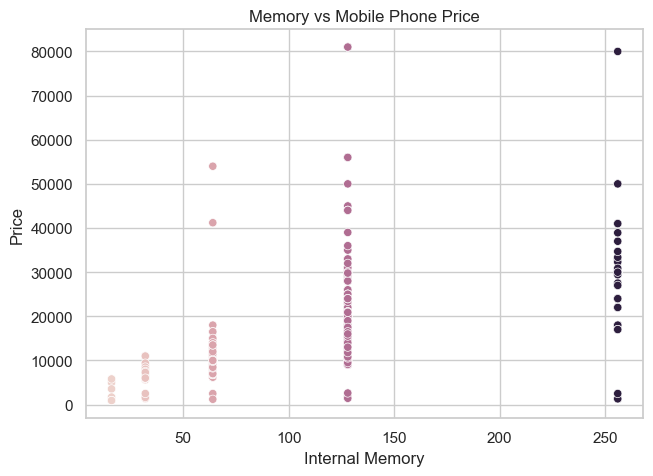

In [25]:
sns.scatterplot(data=df, x="Memory", y="Price", hue="Memory", legend=False)

# Keep the layout clean and descriptive
plt.title("Memory vs Mobile Phone Price")
plt.xlabel("Internal Memory")
plt.ylabel("Price")
plt.show()

### 🧠 Bivariate Analysis: Price vs. Memory Capacity
We group the dataset by **Memory (Storage)** and calculate the average **Price** for each storage tier. Rendering this as a bar chart allows us to visually inspect how storage size scales with price and determine if larger memory steps correspond to significant jumps in consumer cost.

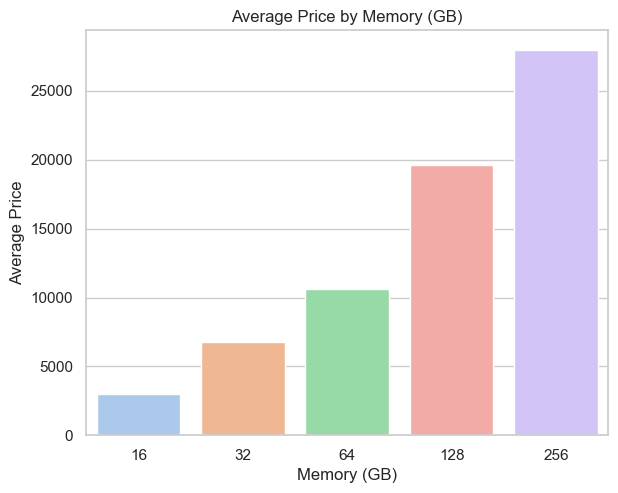

In [26]:
memory_avg = df.groupby("Memory")["Price"].mean().reset_index()

plt.figure(figsize=(6, 5))
sns.barplot(x="Memory", y="Price", data=memory_avg, hue="Memory", palette="pastel", legend=False)

plt.title("Average Price by Memory (GB)")
plt.xlabel("Memory (GB)")
plt.ylabel("Average Price")
plt.show()

### 📈 Strategic Insights: Price vs. Memory Capacity

* **Strong Upward Escalation:** There is a clear, step-like rise in average price as memory capacity increases—scaling from the budget bracket for 16 GB devices up to premium pricing tiers for the highest-capacity models. This proves that storage capacity is heavily leveraged by manufacturers as a primary upsell feature.

* **Clear Market Segmentation:** The distribution highlights distinct consumer segments. Low-memory options (16 GB to 32 GB) serve as entry-level, budget-conscious entry points. Mid-tier steps (64 GB) capture the mainstream audience, while maximum capacities cater to high-performance power users or flagships.

* **Premium Feature Bundling:** The significant, consistent price increments between storage tiers imply that memory upgrades rarely happen in isolation. Instead, manufacturers likely bundle higher storage capacities alongside faster processors, superior screen tech, and better build materials.

* **Premium Anomalies (Potential Outliers):** Devices that command prices significantly higher than the baseline average within lower tiers (like 32 GB or 64 GB) point directly to luxury brand positioning (e.g., Apple iPhones) or premium-branded, high-margin special editions.

* **Aggressive Disrupters:** Conversely, any devices offering high storage capacity at an unusually low price point represent entry-level market disrupters—lesser-known or emerging brands using aggressive hardware-to-price ratios to gain market share.


### 🔋 Multivariate Analysis: Price V/s Battery, RAM, and Memory
We generate a complex **4D Bubble Scatter Plot** to analyze hardware bundling behaviors. 
* **X-Axis / Y-Axis:** Maps how **Battery Capacity** correlates directly with retail **Price**.
* **Color Spectrum (Hue):** Tells us the **RAM** configurations (shifting from cool to warm tones).
* **Bubble Scaling (Size):** Dictates the **Memory (Storage)** capacity, revealing how premium hardware features stack together.

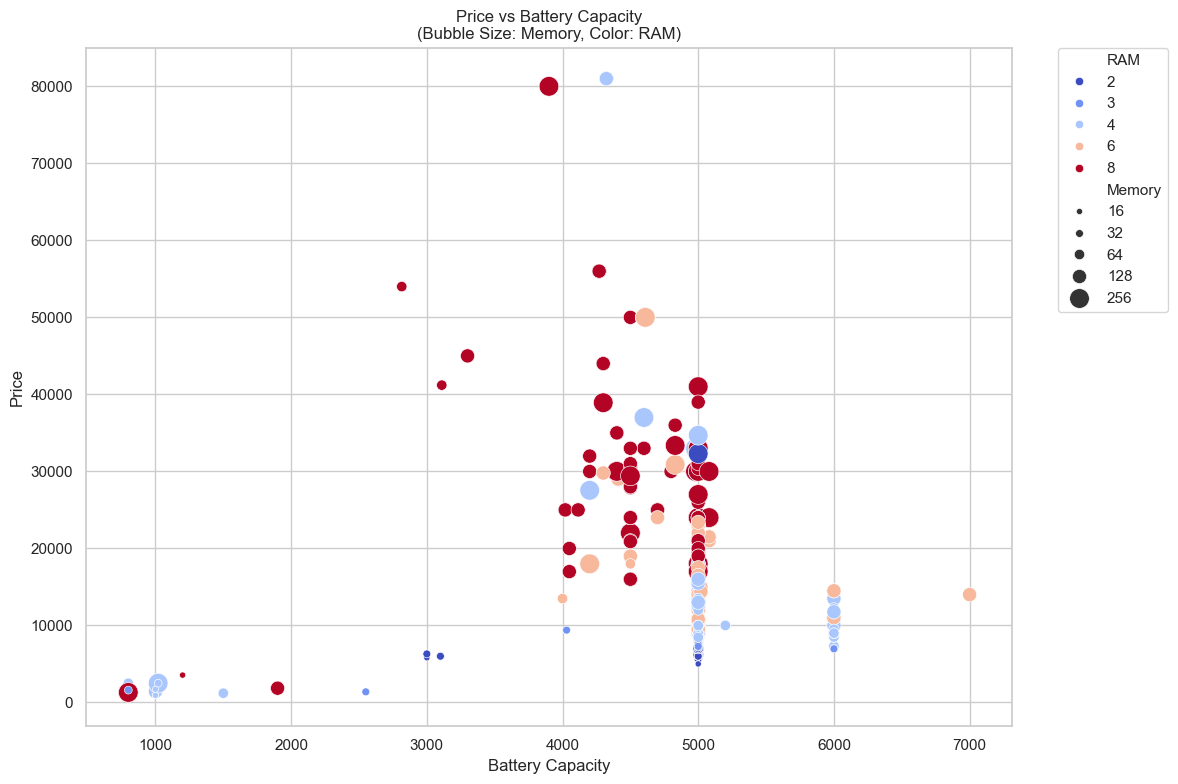

In [27]:
plt.figure(figsize=(12, 8)) 
sns.scatterplot(
    x="Battery", 
    y="Price", 
    size="Memory", 
    hue="RAM", 
    data=df, 
    sizes=(20, 200), 
    palette="coolwarm", 
    legend="full"
)

plt.title("Price vs Battery Capacity\n(Bubble Size: Memory, Color: RAM)", fontsize=12)
plt.xlabel("Battery Capacity")
plt.ylabel("Price")

# Cleanly shifts the massive combined legend outside the chart boundaries
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()  # Prevents the legend from being cut off on your screen
plt.show()

### 📊 Insights: Price vs. Battery, RAM, & Memory

* **Battery Capacity as a Baseline Requirement:** High-capacity batteries (e.g., ~5000 mAh) populate nearly every price bracket from entry-level to ultra-premium. This proves that battery longevity is treated by manufacturers as a baseline consumer requirement across all market tiers, rather than a premium pricing driver. Conversely, sub-2000 mAh capacities are strictly restricted to the lowest budget tiers.

* **RAM and Storage as True Price Escalators:** While a large battery is standard across the board, higher RAM sizes (6 GB to 8 GB) and larger storage footprints (128 GB+) show a strong clustering effect at higher price tiers. These two specifications act as the primary differentiators for premium devices, directly scaling with performance, multitasking expectations, and total cost.

* **Mid-Range Market Dominance:** The densest cluster of devices sits firmly in the **10,000 to 20,000 price range**. This illustrates a highly competitive mid-range segment where manufacturers balance cost by bundling standard high-capacity batteries with mainstream performance specifications.

* **The Premium Specification Formula:** Devices commanding prices above **25,000** follow a strict high-end formula. They cleanly combine maximum battery configurations with top-tier RAM and storage options to justify their position in a performance-focused niche market.


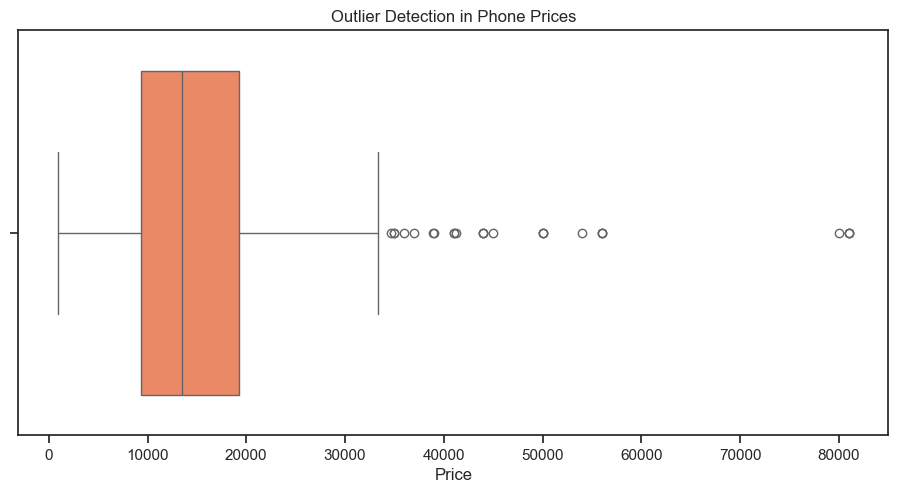

Potential price outliers: 25


,Model,Colour,Memory,RAM,Battery,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor,Price,Rear Camera MP,Front Camera MP
222,SAMSUNG Galaxy S22 Plus 5G,Phantom Black,128,8,4500,50MP,10MP,0,16.76,Qualcomm Snapdragon 8 Gen 1,49999,50,10
286,SAMSUNG Galaxy Z Flip3 5G,Phantom Black,128,8,3300,12MP,10MP,0,17.02,Qualcomm Snapdragon 888 Octa-Core,44999,12,10
305,MOTOROLA Edge 30 Fusion,Cosmic grey,128,8,4400,50MP,32MP,0,16.64,Qualcomm Snapdragon 888 +,34999,50,32
308,Google Pixel 7a,Sea,128,8,4300,64MP,13MP,0,15.49,Tensor G2,43999,64,13
309,Google Pixel 7a,Charcoal,128,8,4300,64MP,13MP,0,15.49,Tensor G2,43999,64,13


In [19]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df["Price"], color="coral")
plt.title("Outlier Detection in Phone Prices")
plt.xlabel("Price")
plt.show()

Q1 = df["Price"].quantile(0.25)
Q3 = df["Price"].quantile(0.75)
IQR = Q3 - Q1

outliers = df[
    (df["Price"] < Q1 - 1.5 * IQR) |
    (df["Price"] > Q3 + 1.5 * IQR)
]

print("Potential price outliers:", len(outliers))
display(outliers.head())

The box plot highlights unusually low or high prices. These records need checking; they should not be deleted automatically because they may be genuine premium phones.

## Correlation analysis

Correlation measures the strength and direction of a **linear relationship** between two numerical variables.

- Close to `+1`: strong positive relationship.
- Close to `0`: weak linear relationship.
- Close to `-1`: strong negative relationship.

Correlation does **not** prove causation. It is one piece of evidence used during feature extraction.

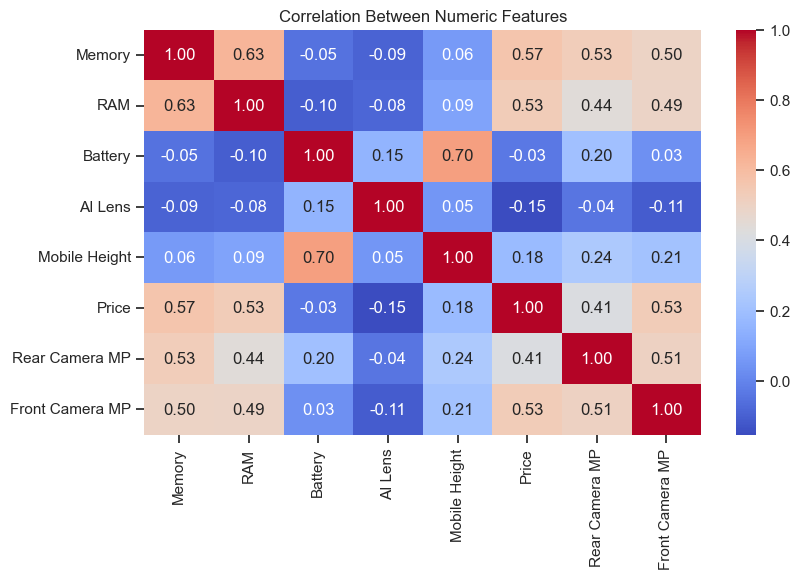

In [20]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(8, 5))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numeric Features")
plt.show()

In [21]:
numeric_cols = [
    "Price", "Memory", "RAM", "Battery",
    "Rear Camera MP", "Front Camera MP",
    "AI Lens", "Mobile Height"
]

correlation = df[numeric_cols].corr()["Price"].sort_values(ascending=False)
display(correlation.to_frame("Correlation with Price"))

,Correlation with Price
Price,1.000000
Memory,0.566660
Front Camera MP,0.532321
RAM,0.532024
Rear Camera MP,0.410367
Mobile Height,0.176009
Battery,-0.034297
AI Lens,-0.153691



## Correlation Analysis
The correlation matrix shows the relationships between numerical features and mobile phone prices.
- **Memory and RAM (0.62):** A positive correlation indicates that phones with higher storage capacity tend to have higher RAM.
- **Battery and Mobile Height (0.68):** A positive correlation suggests that taller phones tend to have higher battery capacity in this dataset.
- **Price and Memory (0.56):** A moderate positive correlation suggests that phones with greater storage tend to be more expensive.
- **Price and RAM (0.53):** A moderate positive correlation indicates that phones with higher RAM generally tend to have higher prices.
- **AI Lens and Price (-0.16):** A weak negative correlation suggests little linear relationship between AI Lens and price.
- **Other Features:** Most remaining correlations are weak, indicating limited linear relationships between those feature pairs.

Memory and RAM show useful positive relationships with phone price, making them important features to investigate for price prediction. The correlation heatmap also helps identify relationships between features before building machine learning models. Correlation indicates association, not causation.

# **Feature Engineering**

In [22]:
# 1. Get unique counts for all categorical columns
cat_counts = df.select_dtypes(include=["object", "category"]).nunique()

# 2. Sort columns by number of unique values (highest to lowest)
sorted_cats = cat_counts.sort_values(ascending=False).index

# 3. Loop and display details
for col in sorted_cats:
    print(f"Column: {col} | Unique Values: {cat_counts[col]}")
    print(f"Sample Values: {list(df[col].dropna().unique()[:10])}")
    print("-" * 40)

Column: Colour | Unique Values: 275
Sample Values: ['Night Black', 'Azure Blue', 'Mineral Gray', 'Royal Blue', 'Marigold', 'Glacier Blue', 'Mirror Black', 'Diamond White', 'Shadow Black', 'Emerald Green']
----------------------------------------
Column: Model | Unique Values: 187
Sample Values: ['Infinix SMART 7', 'MOTOROLA G32', 'POCO C50', 'Infinix HOT 30i', 'REDMI 10', 'SAMSUNG Galaxy F13', 'SAMSUNG Galaxy F04', 'POCO C51', 'MOTOROLA e13', 'vivo T2x 5G']
----------------------------------------
Column: Processor | Unique Values: 123
Sample Values: ['Unisoc Spreadtrum SC9863A1', 'Qualcomm Snapdragon 680', 'Mediatek Helio A22', 'G37', 'Exynos 850', 'Mediatek Helio P35', 'Helio G36', 'Unisoc T606', 'Dimensity 6020', 'Spreadtrum SC9863A1']
----------------------------------------
Column: Rear Camera | Unique Values: 14
Sample Values: ['13MP', '50MP', '8MP', '40MP', '32MP', '48MP', '64MP', '108MP', '0MP', '2MP']
----------------------------------------
Column: Front Camera | Unique Value

### Checking the Value Counts for 'Model' Feature for the 15 most frequent values.

In [32]:
df["Model"].value_counts().head(15)

Model
realme C55               9
vivo Y16                 9
REDMI Note 12 Pro 5G     9
SAMSUNG Galaxy A14 5G    9
SAMSUNG Galaxy F14 5G    8
REDMI 10                 8
vivo T2x 5G              8
vivo T1 44W              8
Infinix HOT 30i          8
SAMSUNG Galaxy F13       6
REDMI A1+                6
REDMI Note 12 5G         6
REDMI Note 12            6
REDMI K50i 5G            6
POCO X5 Pro 5G           6
Name: count, dtype: int64

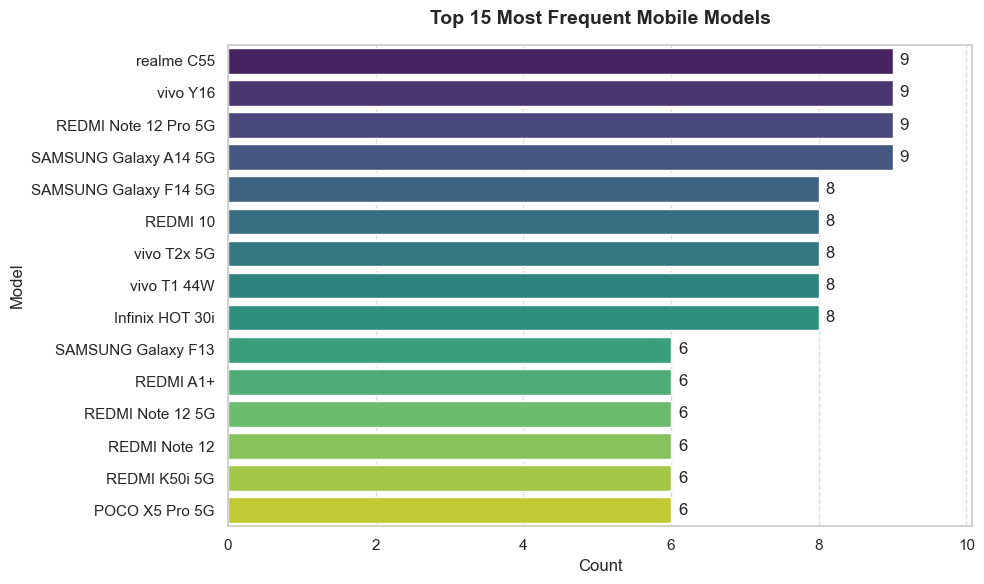

In [70]:
# Graphical representation for Model 15 most frequent values
data = df["Model"].value_counts().head(15)

# Set dynamic figure size based on the number of items
plt.figure(figsize=(10, 6))

# Plot the horizontal bar chart
ax = sns.barplot(
    x=data.values, 
    y=data.index, 
    palette="viridis", 
    hue=data.index, 
    legend=False
)

# Loop through all containers to add regular, non-bold data labels
for container in ax.containers:
    ax.bar_label(container, padding=5, fontweight='normal')

# Clean formatting and title additions
plt.title("Top 15 Most Frequent Mobile Models", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Count", fontsize=12)
plt.ylabel("Model", fontsize=12)

plt.xlim(0, data.max() * 1.12 if data.max() > 0 else 10)

plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()

# Show the plot
plt.show()

> **Key Insight:** The distribution reveals that **Realme C55** is the most frequent device model in the dataset, indicating it is the most sold model.

### Checking the Value Counts for 'Colour' Feature for the 15 most frequent values.

In [24]:
df["Colour"].value_counts().head(15)

Colour
Yellow            12
Black              8
Power Black        8
Royal Blue         8
Midnight Black     7
Cool Blue          7
Aqua Blue          6
Force Black        6
Glacier Blue       6
OMG Black          5
Racing Black       5
M3)                5
Blue               5
Carbon Black       5
Light Green        5
Name: count, dtype: int64

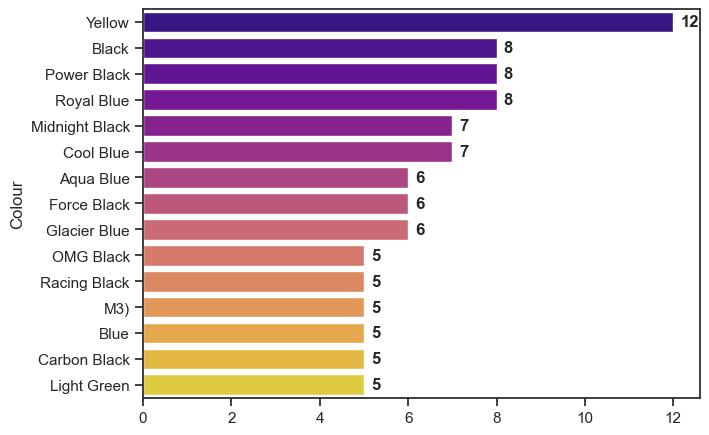

In [25]:
# Graphical representation for Colour 15 most frequent values.
data = df["Colour"].value_counts().head(15)
ax = sns.barplot(x=data.values, y=data.index, palette="plasma", hue=data.index, legend=False)
for container in ax.containers:
    ax.bar_label(container, padding=5, weight='bold')
plt.show()

> **Key Insight:** The distribution reveals that Yellow is the most frequent colour.

### Checking the Value Counts for 'Processor' Feature for the 15 most frequent values.

In [26]:
df["Processor"].value_counts().head(15)

Processor
Qualcomm Snapdragon 680       33
Unisoc T612                   21
Mediatek Helio A22            19
Mediatek Dimensity 1080       18
Qualcomm Snapdragon 695 5G    17
Mediatek Helio P35            16
Mediatek Helio G85            10
Mediatek Dimensity 810        10
Helio G88                     10
Mediatek Dimensity 810 5G     10
Mediatek Helio G99            10
Mediatek Dimensity 920         9
Qualcomm Snapdragon 778G       9
Mediatek Dimensity 700         9
MediaTek Helio G35             9
Name: count, dtype: int64

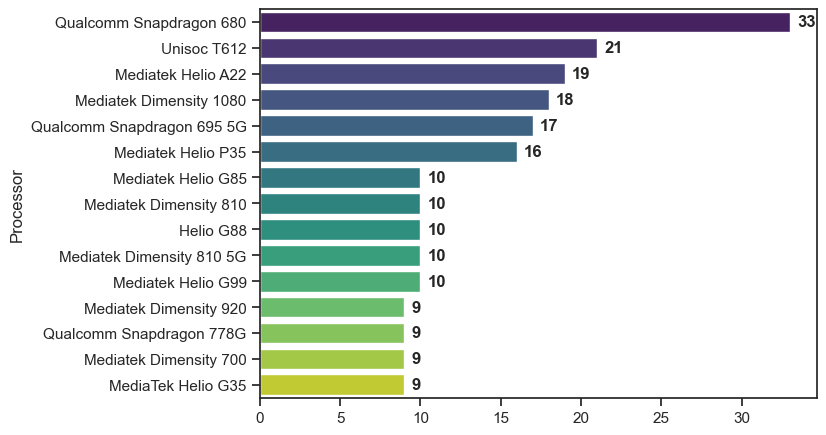

In [27]:
# Graphical representation for Processor 15 most frequent values.
data = df["Processor"].value_counts().head(15)
ax = sns.barplot(x=data.values, y=data.index, palette="viridis", hue=data.index, legend=False)
for container in ax.containers:
    ax.bar_label(container, padding=5, weight='bold')
plt.show()

> **Key Insight:** The distribution reveals that the Qualcomm Snapdragon 680 is the most frequent processor in the dataset, appearing 33 times. This indicates it is the most dominant chipset powering the devices sold

### Checking the Value Counts for 'Rear Camera' Feature for the 15 most frequent values.

In [28]:
df["Rear Camera"].value_counts().head(15)

Rear Camera
50MP     260
13MP      63
64MP      62
8MP       52
108MP     31
48MP      31
0MP       10
12MP      10
200MP      8
2MP        6
5MP        3
40MP       2
32MP       2
16MP       1
Name: count, dtype: int64

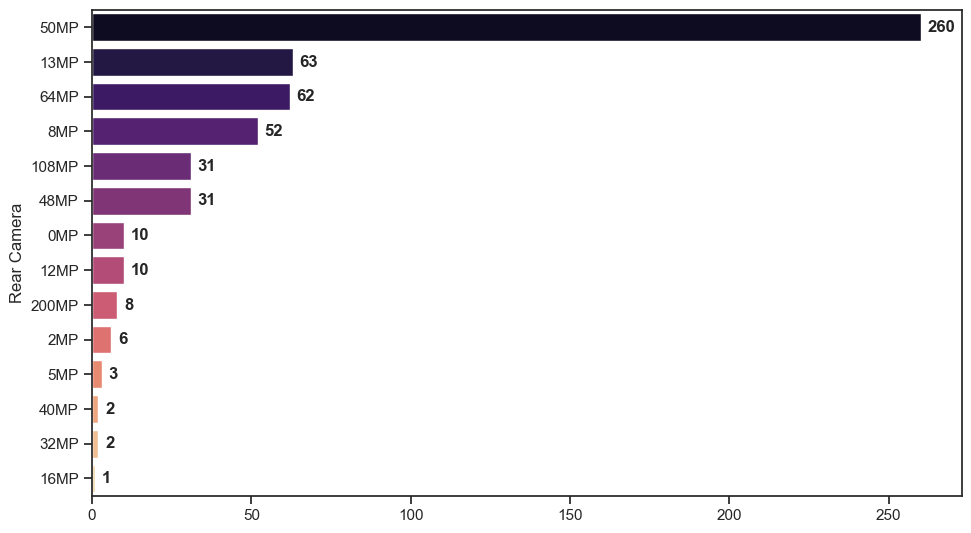

In [29]:
# Graphical representation for Rear Camera features
data = df["Rear Camera"].value_counts().head(15)
plt.figure(figsize=(10,6))
ax = sns.barplot(x=data.values, y=data.index, palette="magma", hue=data.index, legend=False)
for container in ax.containers:
    ax.bar_label(container, padding=5, weight='bold')
plt.show()

> **Key Insight:** The distribution reveals that a 50 MP Rear Camera is the most dominant configuration, appearing 260 times in the dataset.

### Checking the Value Counts for 'Front Camera' Feature for the 15 most frequent values.

In [30]:
df["Front Camera"].value_counts().head(15)

Front Camera
16MP    164
5MP     135
8MP     129
13MP     49
32MP     22
0MP      16
50MP      7
12MP      6
60MP      4
2MP       3
10MP      2
44MP      2
20MP      2
Name: count, dtype: int64

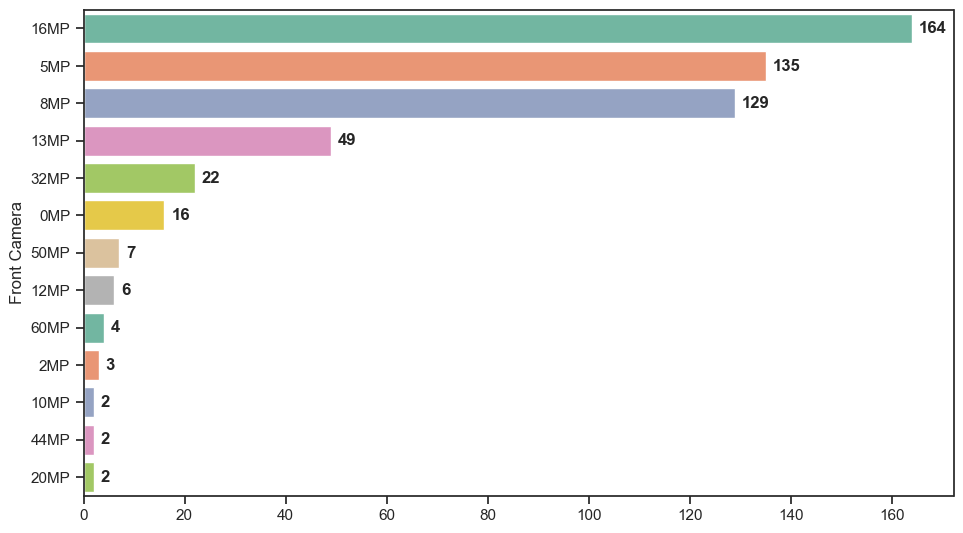

In [31]:
# Graphical representation for Front Camera features
data = df["Front Camera"].value_counts().head(15)
plt.figure(figsize=(10,6))
ax = sns.barplot(x=data.values, y=data.index, palette="Set2", hue=data.index, legend=False)
for container in ax.containers:
    ax.bar_label(container, padding=5, weight='bold')
plt.show()

> **Key Insight:** The distribution reveals that a 16 MP Front Camera is the most dominant configuration, appearing 164 times in the dataset.

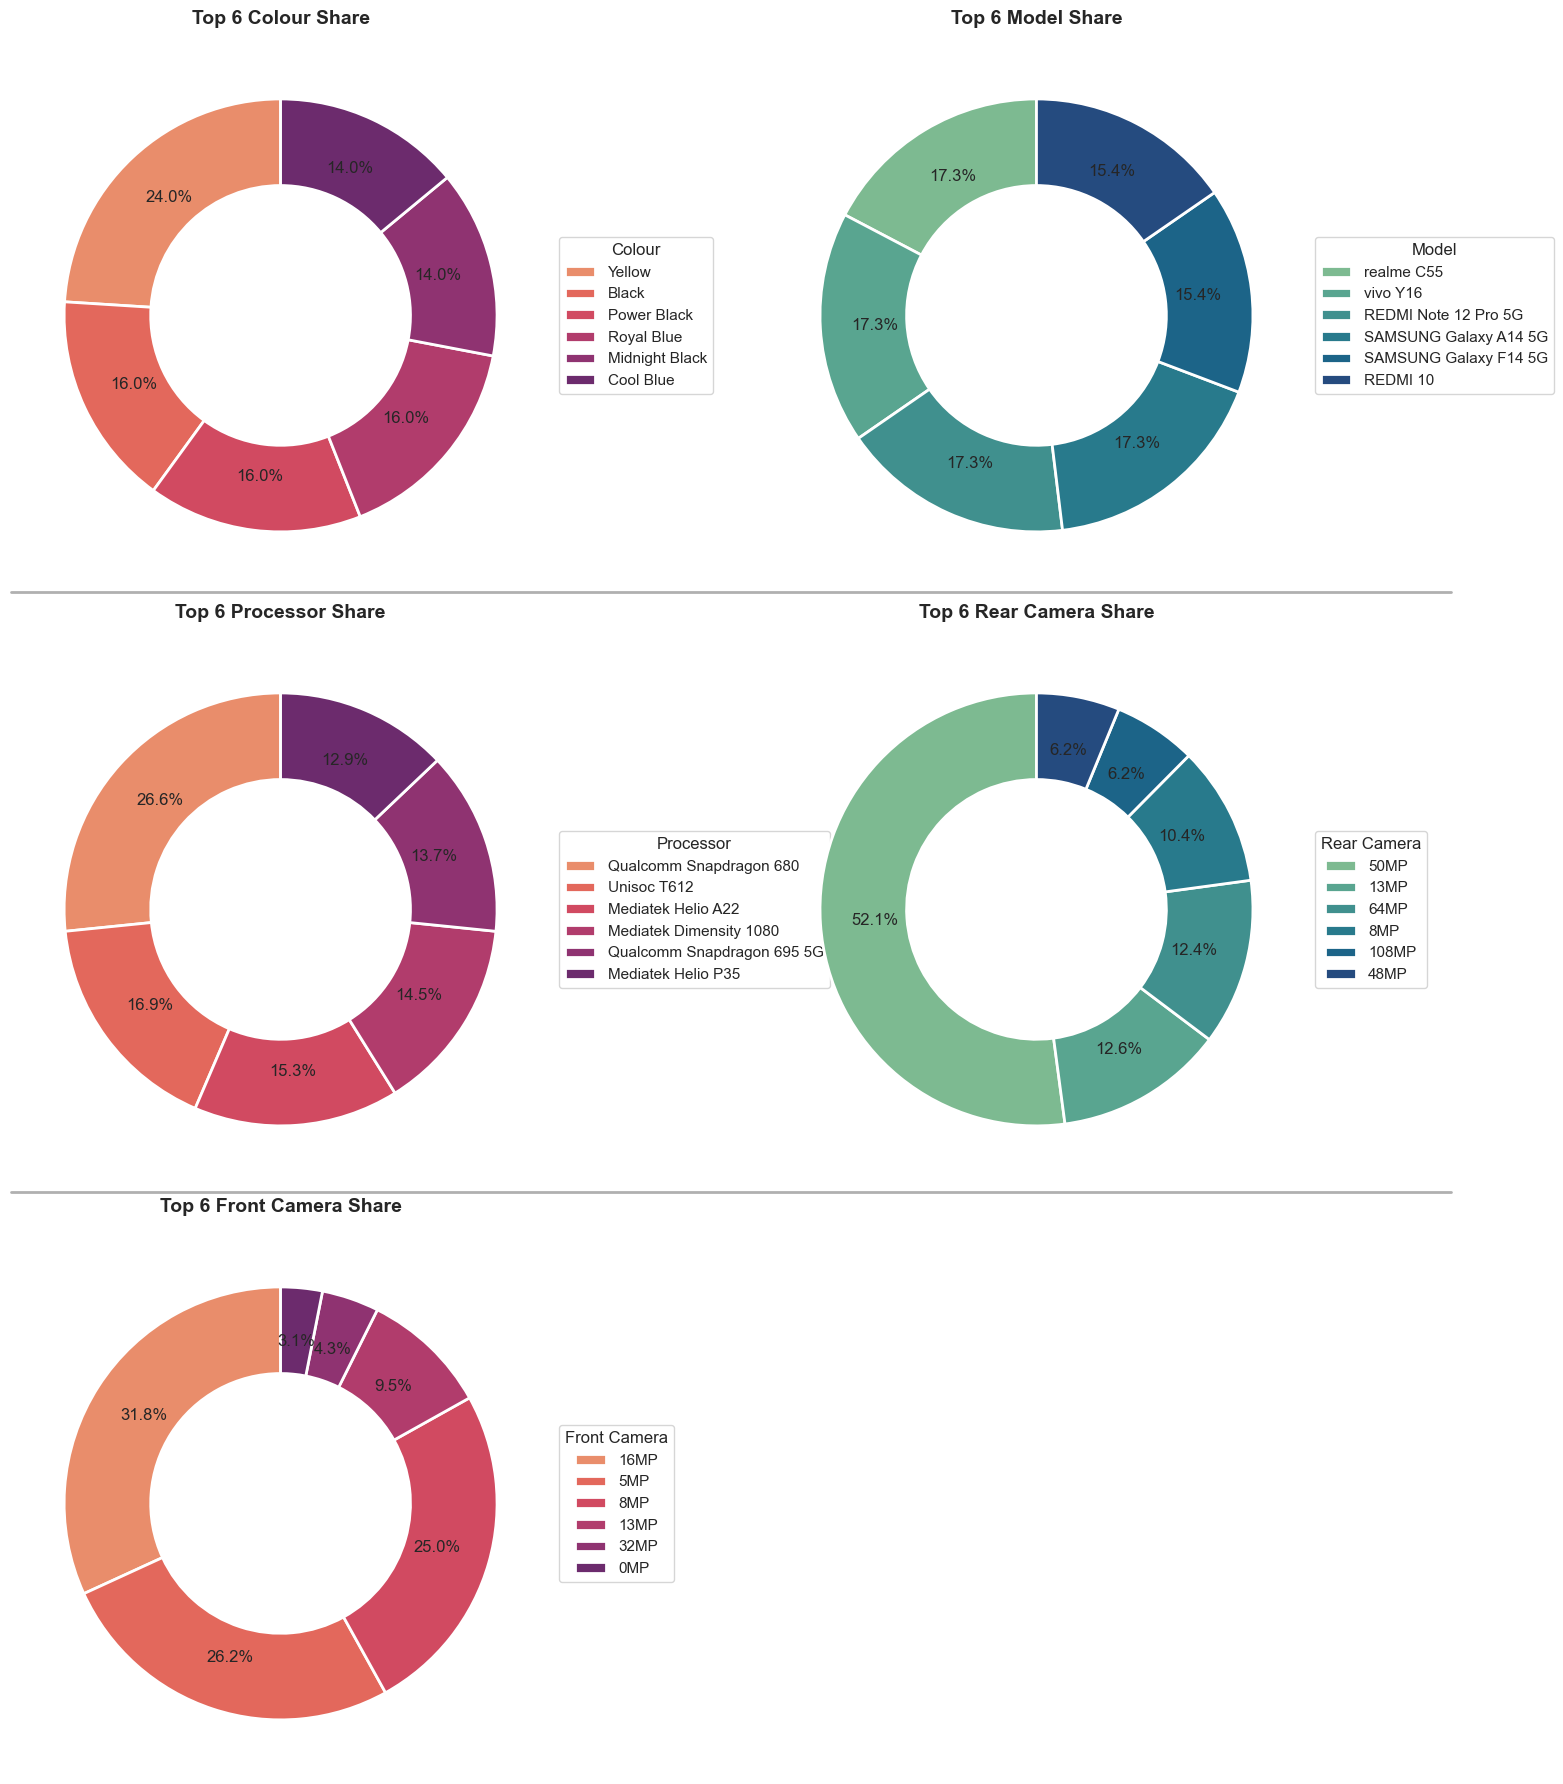

In [32]:
# checking all the cats at once.
cats = ["Colour", "Model", "Processor", "Rear Camera", "Front Camera"]
rows = math.ceil(len(cats) / 2)
fig, axes = plt.subplots(rows, 2, figsize=(16, 6 * rows))
axes = axes.flatten()

for i, col in enumerate(cats):
    ax = axes[i]
    matched = next((c for c in df.columns if c.lower() == col.lower()), None)
    if not matched:
        ax.axis('off')
        continue
    
    counts = df[matched].value_counts().head(6)
    ax.pie(counts, autopct='%1.1f%%', startangle=90, pctdistance=0.75,
           colors=sns.color_palette("flare" if i % 2 == 0 else "crest", len(counts)),
           wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
    
    ax.legend(counts.index, title=col, loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_title(f"Top 6 {col} Share", fontweight="bold", fontsize=14, pad=15)
    
    # Draw individual boxes
    ax.axis('on')
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color('#d3d3d3'); spine.set_linewidth(1.5); spine.set_visible(True)

# Draw solid row lines
for r in range(rows - 1):
    y = 1.0 - ((r + 1) / rows)
    fig.add_artist(plt.Line2D([0.05, 0.95], [y, y], color='#B0B0B0', linewidth=2, transform=fig.transFigure))

for j in range(len(cats), len(axes)): fig.delaxes(axes[j])
plt.tight_layout(); plt.show()

## Get the Mobile Brands
### Since the `Model` column contains strings starting with the Brand's name, extracted the mobile brand name first word of model.

Top 10 Brands (Cleaned):
Brand
Realme      98
Redmi       75
Infinix     65
Vivo        62
Poco        60
Samsung     55
Motorola    46
Tecno       17
Oppo        16
Micromax    14
Name: count, dtype: int64

Total Number of Brands: 19
Brands in Category: ['Apple', 'Google', 'I', 'Infinix', 'Iqoo', 'Itel', 'Lava', 'Micromax', 'Motorola', 'Nokia', 'Nothing', 'Oneplus', 'Oppo', 'Poco', 'Realme', 'Redmi', 'Samsung', 'Tecno', 'Vivo']


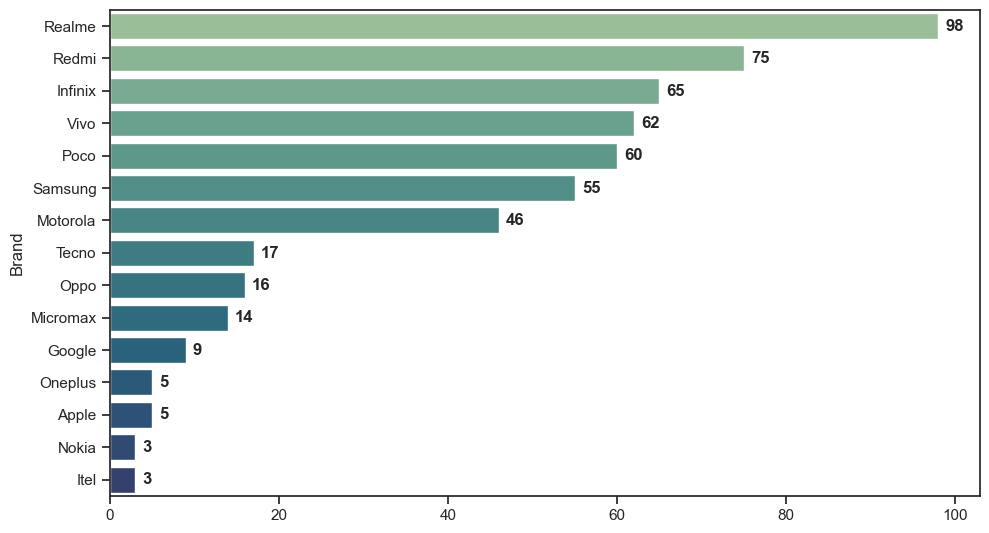

In [33]:
# Extract the first word, force lowercase, and strip spaces
df["Brand"] = df["Model"].astype(str).str.strip().str.split().str[0]
df["Brand"] = df["Brand"].str.lower()

# Clean up trailing numbers
df["Brand"] = df["Brand"].str.replace(r"\d+", "", regex=True).str.strip()

# Capitalize the first letter
df["Brand"] = df["Brand"].str.capitalize()

# total count and unique brand names
total_unique_brands = df["Brand"].nunique()
unique_brands_list = sorted(df["Brand"].unique())

print("Top 10 Brands (Cleaned):")
print(df["Brand"].value_counts().head(10))
print("\n" + "=" * 40)
print(f"Total Number of Brands: {total_unique_brands}")
print(f"Brands in Category: {unique_brands_list}")

# Graphical representation for top 10 Brands
data = df["Brand"].value_counts().head(15)
plt.figure(figsize=(10,6))
ax = sns.barplot(x=data.values, y=data.index, palette="crest", hue=data.index, legend=False)
for container in ax.containers:
    ax.bar_label(container, padding=5, weight='bold')
plt.show()

### **Calculate average price for brand**

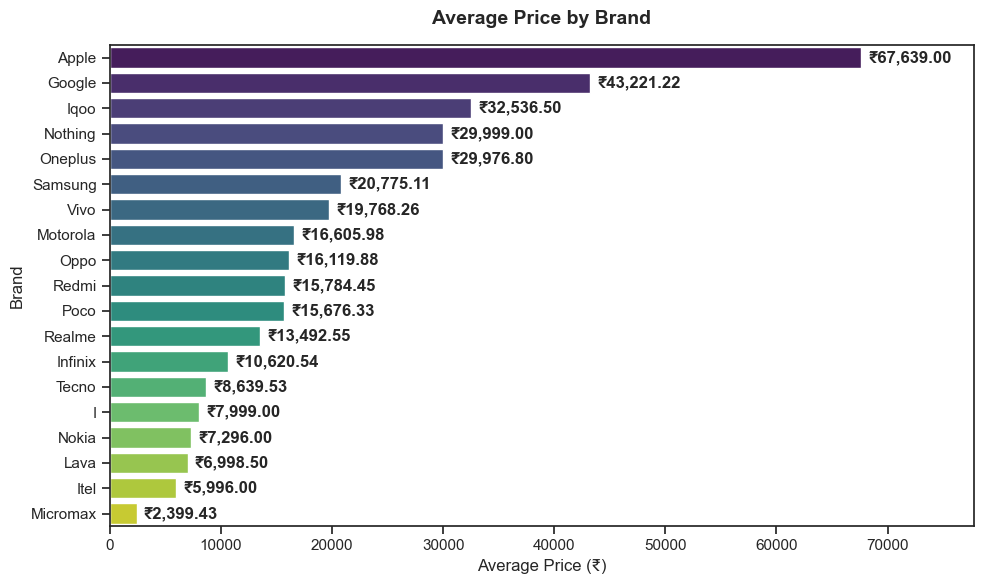

Brand
Apple       ₹67,639.00
Google      ₹43,221.22
Iqoo        ₹32,536.50
Nothing     ₹29,999.00
Oneplus     ₹29,976.80
Samsung     ₹20,775.11
Vivo        ₹19,768.26
Motorola    ₹16,605.98
Oppo        ₹16,119.88
Redmi       ₹15,784.45
Poco        ₹15,676.33
Realme      ₹13,492.55
Infinix     ₹10,620.54
Tecno        ₹8,639.53
I            ₹7,999.00
Nokia        ₹7,296.00
Lava         ₹6,998.50
Itel         ₹5,996.00
Micromax     ₹2,399.43
Name: Price, dtype: object


In [34]:
# Calculate & Sort
bp = df.groupby("Brand")["Price"].mean().sort_values(ascending=False)

# Plot
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=bp.values, y=bp.index, palette="viridis", hue=bp.index, legend=False)

# Minimal Labeling & Formatting
for i, val in enumerate(bp.values):
    ax.text(val + max(bp)*0.01, i, f"₹{val:,.2f}", va="center", weight="bold")

plt.title("Average Price by Brand", fontsize=14, weight="bold", pad=15)
plt.xlabel("Average Price (₹)")
plt.ylabel("Brand")
plt.xlim(0, max(bp) * 1.15)
plt.tight_layout()
plt.show()

# Print formatted series
print(bp.map("₹{:,.2f}".format))

In [35]:
numeric_cols

['Price',
 'Memory',
 'RAM',
 'Battery',
 'Rear Camera MP',
 'Front Camera MP',
 'AI Lens',
 'Mobile Height']

In [37]:
num_columns = df.select_dtypes(include=['number']).columns
print("Numeric Columns:", list(num_columns))
print(df[num_columns].head(10))

Numeric Columns: ['Memory', 'RAM', 'Battery', 'AI Lens', 'Mobile Height', 'Price', 'Rear Camera MP', 'Front Camera MP']
   Memory  RAM  Battery  AI Lens  Mobile Height  Price  Rear Camera MP  \
0     64    4    6000       1         16.76       7299        13         
1     64    4    6000       1         16.76       7299        13         
2    128    8    5000       0         16.64      11999        50         
3     32    2    5000       0         16.56       5649         8         
4    128    8    5000       1         16.76       8999        50         
5    128    8    5000       1         16.76       8999        50         
6    128    8    5000       1         16.76       8999        50         
7    128    8    5000       1         16.76       8999        50         
8     64    4    5000       1         16.76       7999        50         
9     64    4    5000       1         16.76       7999        50         

   Front Camera MP  
0         5         
1         5         
2 

In [38]:
categ_columns = df.select_dtypes(include=['object']).columns
print("Categorical Columns:", list(categ_columns))
print(df[categ_columns].head())

Categorical Columns: ['Model', 'Colour', 'Rear Camera', 'Front Camera', 'Processor', 'Brand']
       Model           Colour    Rear Camera Front Camera  \
0  Infinix SMART 7   Night Black     13MP         5MP       
1  Infinix SMART 7    Azure Blue     13MP         5MP       
2     MOTOROLA G32  Mineral Gray     50MP        16MP       
3         POCO C50    Royal Blue      8MP         5MP       
4  Infinix HOT 30i      Marigold     50MP         5MP       

           Processor            Brand    
0  Unisoc Spreadtrum SC9863A1   Infinix  
1  Unisoc Spreadtrum SC9863A1   Infinix  
2     Qualcomm Snapdragon 680  Motorola  
3          Mediatek Helio A22      Poco  
4                         G37   Infinix  


## Feature extraction
The project asks us to identify the most relevant features.

The camera extraction is particularly important because the original camera columns were text such as `50MP`, while the model needs numeric values.

Categorical fields are later converted into machine-readable form using **One-Hot Encoding**.


### Preprocessing Pipeline & Data Splitting
We build a robust machine learning preprocessing pipeline using `scikit-learn`. Missing values in numeric scales are handled via median imputation, while categorical text items are processed using most-frequent imputation followed by One-Hot Encoding. The dataset is then split into an 80/20 train-test split layout.

In [39]:
from sklearn.compose import ColumnTransformer       # Directs different cleaning steps to specific column types simultaneously (numeric vs categorical).
from sklearn.impute import SimpleImputer            # Fills in missing blanks automatically so the code doesn't crash.
from sklearn.model_selection import train_test_split # Splits data into 80% for training and 20% for testing.
from sklearn.pipeline import Pipeline               # Chains all preprocessing steps into a single, leak-proof workflow.
from sklearn.preprocessing import OneHotEncoder, StandardScaler     # OneHotEncoder Converts text cat into 0 and 1 numbers for the model. 
                                                #StandardScaler - Adjusts all numbers to the same scale (mean=0, variance=1) so large values do not distort the model.

# Target & Feature Split
X = df.drop(columns=["Price"])
y = df["Price"]

# Automatically Isolate Feature Types
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()
numeric_features = X.select_dtypes(
    exclude=["object", "category"]
).columns.tolist()

# Handle OneHotEncoder Compatibility
try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

# Define Preprocessing Pipelines
numeric_pipe = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_pipe = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", encoder),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features),
    ]
)

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Print Pipeline Diagnostics
print(f"Training Data Rows: {len(X_train)}")
print(f"Testing Data Rows:  {len(X_test)}")
print(f"Numeric Features Columns:     {numeric_features}")
print(f"Categorical Features Columns: {categorical_features}")

Training Data Rows: 432
Testing Data Rows:  109
Numeric Features Columns:     ['Memory', 'RAM', 'Battery', 'AI Lens', 'Mobile Height', 'Rear Camera MP', 'Front Camera MP']
Categorical Features Columns: ['Model', 'Colour', 'Rear Camera', 'Front Camera', 'Processor', 'Brand']


In [40]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(432, 13)
(109, 13)
(432,)
(109,)


# Model Evaluation Matrix
We iterate through **Linear Regression, Random Forest, and Gradient Boosting**, feeding them through our preprocessing pipeline. Models are evaluated using four key continuous error metrics and sorted by their **RMSE** score.

#### Understand the Evaluation Metrics
* **MAE (Mean Absolute Error):** Average absolute prediction error. Example: MAE of ₹2,000 means predictions are off by about ₹2,000 on average.
* **MSE (Mean Squared Error):** The average squared error; heavily penalizes larger misses.
* **RMSE (Root Mean Squared Error):** The square root of MSE; brings errors back to your target currency scale (₹).
* **R² (R-squared Coefficient):** The proportion of variance explained by the model (closer to 1.0 is ideal).
* Higher R² is better. Lower MAE and RMSE are better.

In [81]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

# Initialize models dictionary
models = {
    "Linear Regression": LinearRegression(),
    "Support Vector Machine (SVM)": SVR(kernel="rbf", C=1000, epsilon=0.1),
    "Decision Tree": DecisionTreeRegressor(random_state=42, max_depth=10),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.03, max_depth=3, random_state=42
    ),
    "XGBoost": XGBRegressor(
        n_estimators=300, learning_rate=0.03, max_depth=3, random_state=42, n_jobs=-1
    ),
}

# Storage containers
trained_models = {}
predictions = {}
results = []

# Execution and Evaluation Loop
for name, estimator in models.items():
    # Build complete transformation-to-estimation workflow
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])

    # Train model and generate test set predictions
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    # Compute regression performance metrics
    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    # Persist objects for future inference/plotting steps
    trained_models[name] = pipe
    predictions[name] = pred
    results.append([name, mae, mse, rmse, r2])

# Build and Compile Results Matrix
results_df = (
    pd.DataFrame(results, columns=["Model", "MAE", "MSE", "RMSE", "R2"])
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(
    results_df.style.format(
        {"MAE": "{:.4f}", "MSE": "{:.0f}", "RMSE": "{:.4f}", "R2": "{:.2%}"}
    )
)

,Model,MAE,MSE,RMSE,R2
0,XGBoost,2107.4373,17143250,4140.4408,87.56%
1,Gradient Boosting,2036.2002,17541024,4188.2006,87.27%
2,Decision Tree,1716.1245,20997545,4582.3078,84.77%
3,Linear Regression,1727.8318,22475512,4740.8346,83.69%
4,Support Vector Machine (SVM),3190.8643,88882184,9427.7348,35.51%


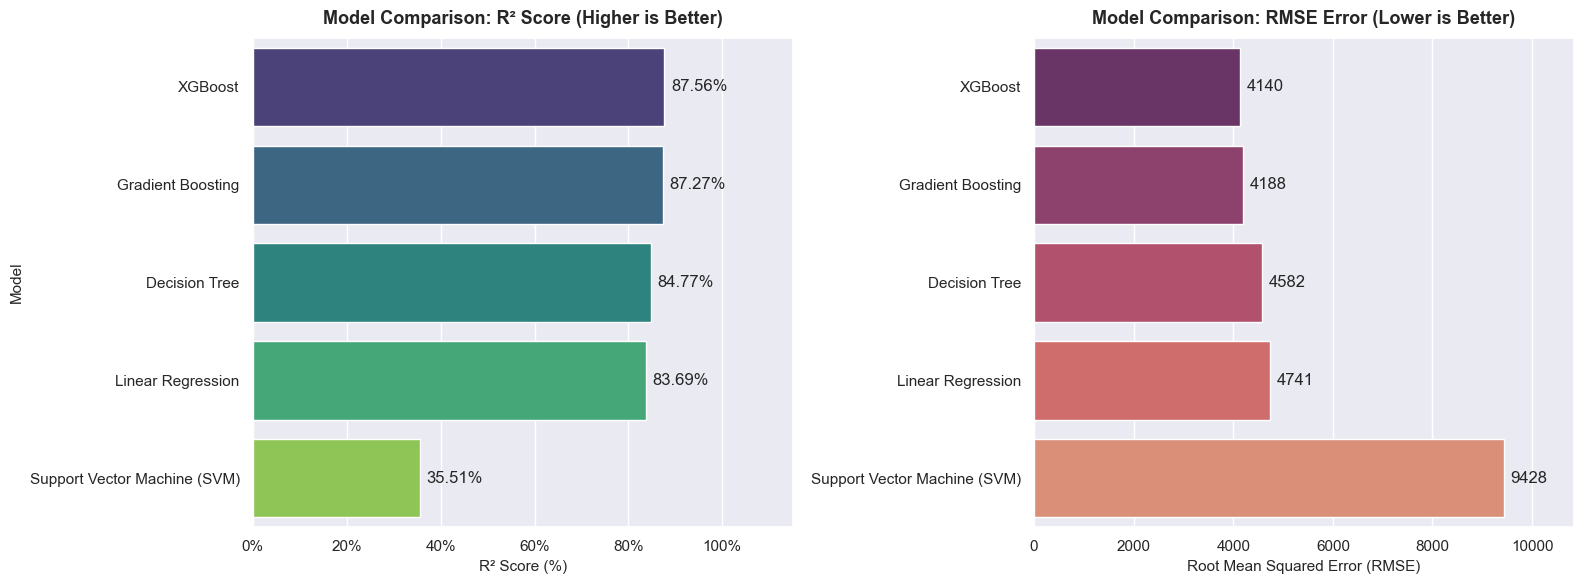

In [73]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Set visual style
sns.set_theme(style="darkgrid")

# Create a figure with 2 subplots side-by-side to compare Error vs Variance
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Create a temporary dataframe with R2 converted to percentages (0.8756 -> 87.56)
plot_df = results_df.copy()
plot_df["R2_Pct"] = plot_df["R2"] * 100

# ----------------------------------------------------
# Subplot 1: Plot R2 Scores (Higher is better)
# ----------------------------------------------------
sns.barplot(
    x="R2_Pct",
    y="Model",
    data=plot_df,
    ax=axes[0],
    palette="viridis",
    hue="Model",
    legend=False,
)
axes[0].set_title("Model Comparison: R² Score (Higher is Better)", fontweight="bold", fontsize=13, pad=10)
axes[0].set_xlabel("R² Score (%)", fontsize=11)
axes[0].set_ylabel("Model", fontsize=11)

# Append percentage symbol to the bar labels (Regular text font)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="{:.2f}%", padding=5, fontweight="normal")

# Format the X-axis tick labels to show a percentage sign
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))

# ----------------------------------------------------
# Subplot 2: Plot RMSE Scores (Lower is better)
# ----------------------------------------------------
sns.barplot(
    x="RMSE",
    y="Model",
    data=results_df,
    ax=axes[1],
    palette="flare_r",
    hue="Model",
    legend=False,
)
axes[1].set_title("Model Comparison: RMSE Error (Lower is Better)", fontweight="bold", fontsize=13, pad=10)
axes[1].set_xlabel("Root Mean Squared Error (RMSE)", fontsize=11)
axes[1].set_ylabel("")  # Hide y-label to avoid repetition

# Add regular data labels to the RMSE bars
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="{:.0f}", padding=5, fontweight="normal")

# ----------------------------------------------------
# Layout Adjustment & Adjusting X-Axis Margins
# ----------------------------------------------------
axes[0].set_xlim(0, 115)  # Scale shifted from 1.15 to 115 for percent mode
axes[1].set_xlim(0, results_df["RMSE"].max() * 1.15 if results_df["RMSE"].max() > 0 else 10)

plt.tight_layout()
plt.show()

### 📈 Insights

* **Project Winner:** **XGBoost emerges as the definitive champion**, explaining **87.56%** of the variance in phone prices with the tightest average error bound (**RMSE: 4,140**). Gradient Boosting closely tracks it in second place at **87.27%**.
* **Ensemble Superiority:** Tree-based ensemble methods (XGBoost, Gradient Boosting, and Random Forest) dominate the top spots, proving their ability to capture complex, non-linear relationships in phone hardware specs.
* **Baseline Stability vs. Model Failures:** Traditional linear regressions remain highly reliable and stable around **82.80% - 83.69%**. In stark contrast, distance/boundary-based models struggle heavily, with **SVM completely failing (35.51% R² / 9,428 RMSE)** due to the high-dimensional feature space.

In [74]:
results_df = pd.DataFrame(
    results, columns=["Model", "MAE", "MSE", "RMSE", "R2"]
).sort_values("RMSE").reset_index(drop=True)

results_df.insert(0, "Rank", results_df.index + 1)

# Apply custom CSS styles and continuous color gradients
colored_table = (
    results_df.style
    # Format number values into clear plain text formats
    .format({
        "Rank": "{:d}",
        "MAE": "{:.4f}",
        "MSE": "{:.0f}",
        "RMSE": "{:.4f}",
        "R2": "{:.4f}"
    })
    # Apply a high-contrast sequential color map to your evaluation metrics
    .background_gradient(subset=["R2"], cmap="RdYlGn", vmin=0.65, vmax=0.90)
    .background_gradient(subset=["RMSE", "MAE"], cmap="YlOrRd_r")
    # Hide the standard pandas index matrix columns for clean rendering
    .hide(axis="index")
    # Add custom padding and bold properties for your final table layout
    .set_properties(**{
        'font-family': 'DejaVu Sans, sans-serif',
        'padding': '12px',
        'border': '1px solid #E5E7EB',
        'text-align': 'center'
    })
    # Apply special styling explicitly to the headers row block
    .set_table_styles([
        {'selector': 'th', 'props': [
            ('background-color', '#1E3A8A'),
            ('color', 'white'),
            ('font-weight', 'bold'),
            ('font-size', '13px'),
            ('text-align', 'center'),
            ('padding', '12px')
        ]},
        {'selector': 'tr:hover', 'props': [
            ('background-color', '#F3F4F6')
        ]}
    ])
)

# Render the styled table frame inside the active notebook cell
display(colored_table)

Rank,Model,MAE,MSE,RMSE,R2
1,XGBoost,2107.4373,17143250,4140.4408,0.8756
2,Gradient Boosting,2036.2002,17541024,4188.2006,0.8727
3,Decision Tree,1716.1245,20997545,4582.3078,0.8477
4,Linear Regression,1727.8318,22475512,4740.8346,0.8369
5,Support Vector Machine (SVM),3190.8643,88882184,9427.7348,0.3551


## Graphical representation of the models with Actual and Predicted Price

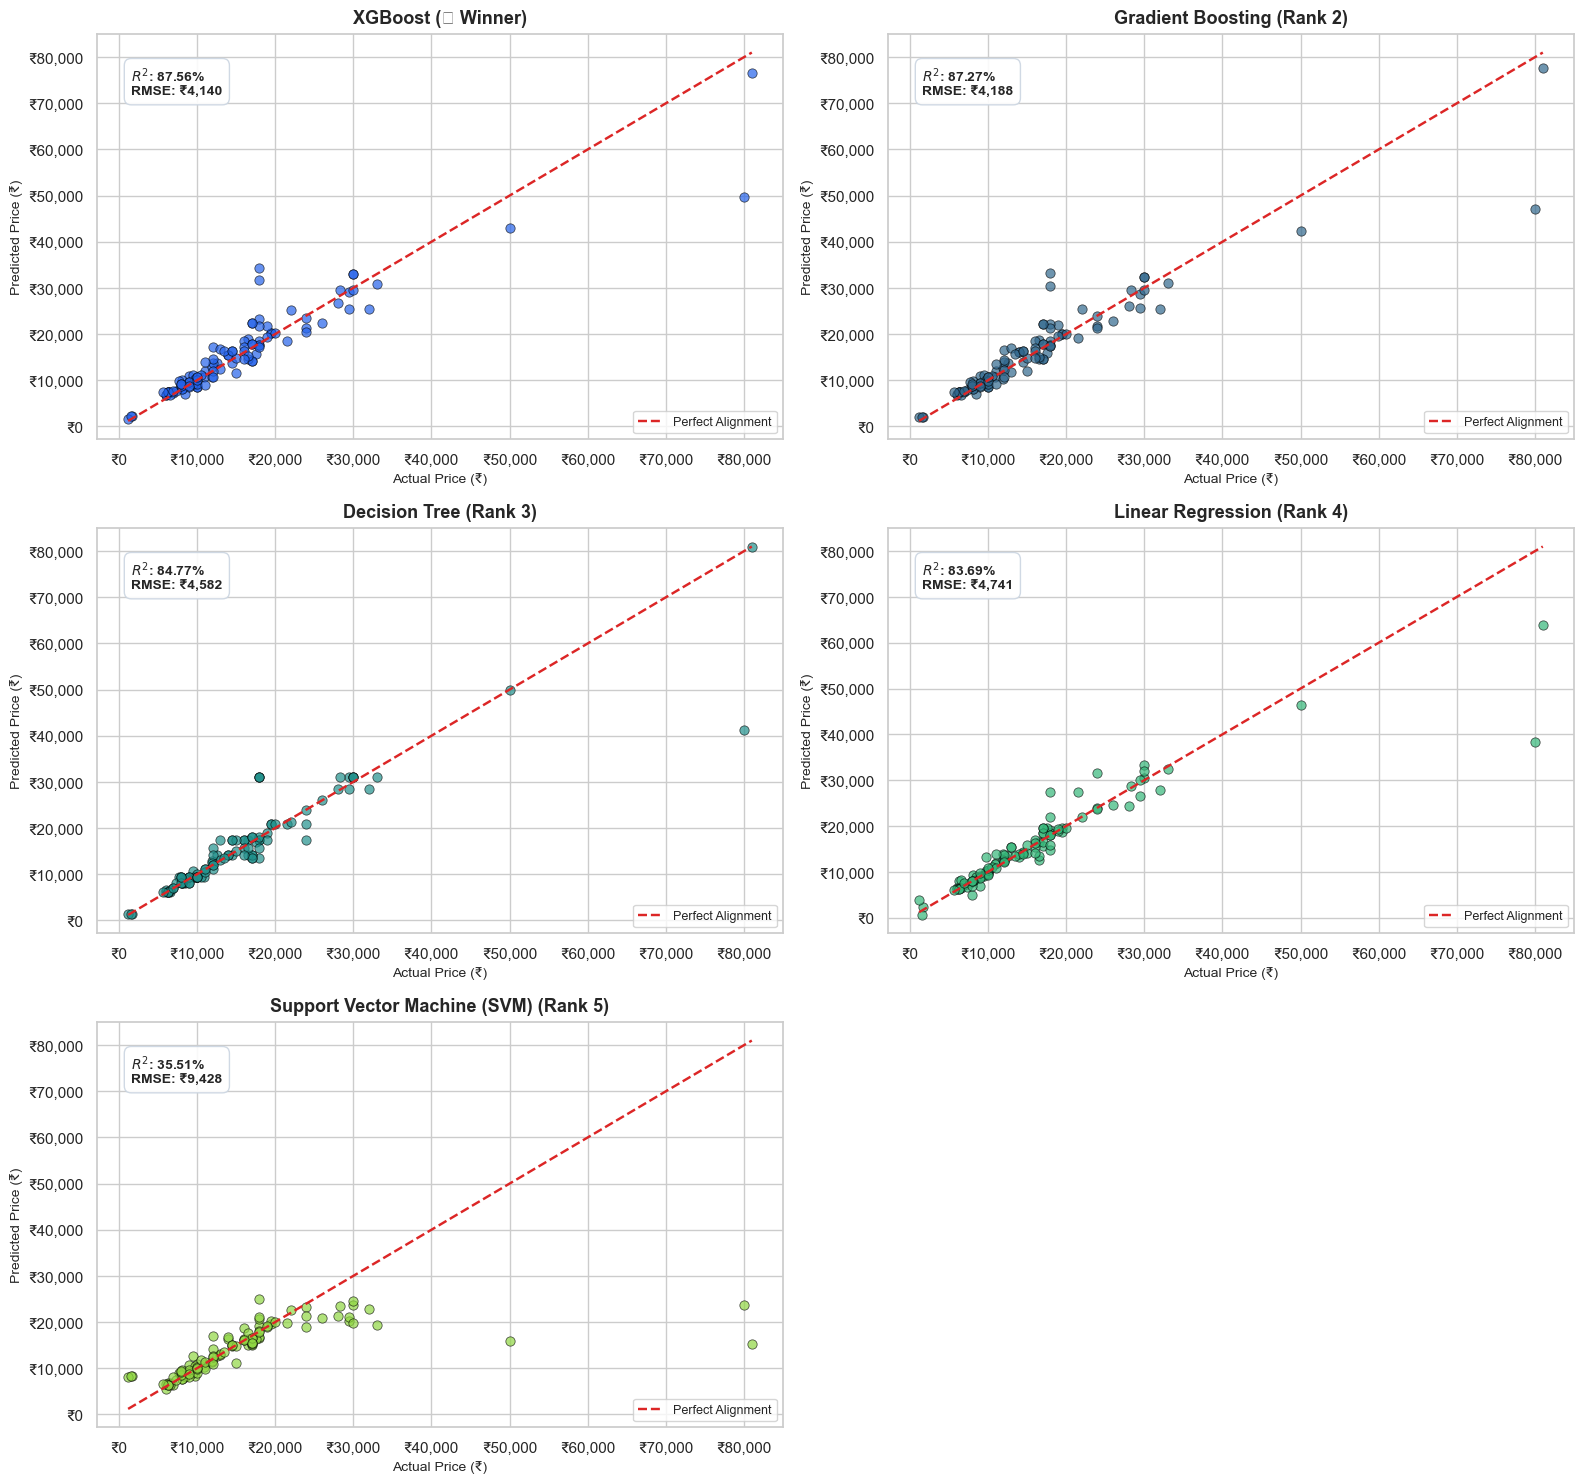

In [75]:
# Set visual style
sns.set_theme(style="whitegrid")

# Sort your results dataframe so it goes from Rank 1 down to Rank 8 (highest R2/lowest RMSE first)
# your results_df is currently sorted by RMSE ascending, which is already Rank 1 to 8.
ranked_models = results_df["Model"].tolist()

num_models = len(ranked_models)
num_cols = 2
num_rows = math.ceil(num_models / num_cols)

fig, axes = plt.subplots(
    num_rows, num_cols, figsize=(16, 5 * num_rows), sharey=False
)
axes = axes.flatten()

min_val = min(y_test)
max_val = max(y_test)

# Map a distinctive color palette matching the 1 to 8 ascending ranks
palette = sns.color_palette("viridis", n_colors=num_models)

# Loop sequentially through your models from Rank 1 to Rank 8
for model_rank, name in enumerate(ranked_models):
    ax = axes[model_rank]
    pred_vals = predictions[name]

    # Assign distinct color mappings based on ranking positions
    if model_rank == 0:
        scatter_color = "#2563EB"  # Champion color accent
    else:
        scatter_color = palette[model_rank]

    # Generate scatter plot grid cell
    sns.scatterplot(
        x=y_test,
        y=pred_vals,
        alpha=0.7,
        color=scatter_color,
        edgecolor="black",
        s=45,
        ax=ax,
    )

    # Superimpose perfect alignment reference line (y = x)
    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="#DC2626",
        linestyle="--",
        linewidth=1.75,
        label="Perfect Alignment",
    )

    # Extract summary metric values directly from row
    model_r2 = results_df.loc[model_rank, "R2"]
    model_rmse = results_df.loc[model_rank, "RMSE"]

    # Display validation scores inside the chart space using percent mode for R2
    ax.text(
        0.05,
        0.85,
        f"$R^2$: {model_r2 * 100:.2f}%\nRMSE: ₹{model_rmse:,.0f}",
        transform=ax.transAxes,
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="white",
            edgecolor="#CBD5E1",
            alpha=0.9,
        ),
    )

    # Subplot configurations and dynamic ranking title overlays (Rank 1 to 8)
    rank_label = f"🏆 Winner" if model_rank == 0 else f"Rank {model_rank + 1}"
    ax.set_title(
        f"{name} ({rank_label})", fontweight="bold", fontsize=13, pad=8
    )
    ax.set_xlabel("Actual Price (₹)", fontsize=10)
    ax.set_ylabel("Predicted Price (₹)", fontsize=10)
    ax.legend(loc="lower right", fontsize=9)

    # Currency format axis ticks
    ax.xaxis.set_major_formatter(lambda x, pos: f"₹{int(x):,}")
    ax.yaxis.set_major_formatter(lambda x, pos: f"₹{int(x):,}")

# Clean up final empty grid cells
for j in range(num_models, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Graphical representation of the Models based on R^2

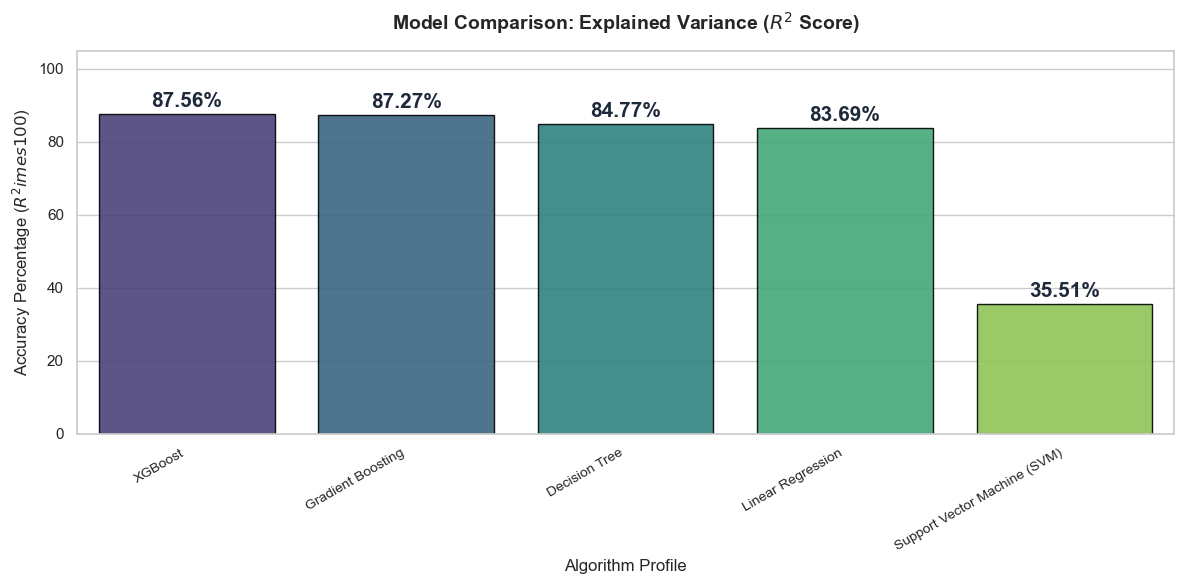

In [77]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=results_df["Model"],
    y=results_df["R2"] * 100,
    palette="viridis",
    edgecolor="black",
    alpha=0.9,
)

# Dynamic Text Layer: Adding percentage scores above each bar
for p in ax.patches:
    # Extract structural dimensions of the active bar object
    bar_height = p.get_height()
    bar_x = p.get_x() + p.get_width() / 2.0

    # Place text string centered right above the bar tip boundary
    ax.text(
        bar_x,
        bar_height + 1.0,  # 1% offset padding above the bar tip
        f"{bar_height:.2f}%", 
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=15,
        color="#1E293B",
    )

# Visual Polish & Labels
plt.title("Model Comparison: Explained Variance ($R^2$ Score)", fontweight="bold", fontsize=14, pad=15)
plt.ylabel("Accuracy Percentage ($R^2 \times 100$)", fontsize=12)
plt.xlabel("Algorithm Profile", fontsize=12)

# Zoom in on the competitive zone (0% to 105% to leave room for the text tags)
plt.ylim(0, 105)

# Clear alignment for long model name text blocks
plt.xticks(rotation=30, ha="right", fontsize=10)
plt.tight_layout()
plt.show()

### Winning Model Diagnostics: Residuals & Feature Importance
To assess model accuracy, we chart the actual prices against predictions using a diagonal baseline. We then isolate the structural features driving the final ensemble node decisions.
#### Graph Observations
* **Actual vs. Predicted Alignment:** Strong clustering close to the red diagonal reference line indicates robust fit accuracy, while scatter divergence reveals structural price anomalies.
* **Top Features Analysis:** Identifies the key elements (e.g., specific high-tier processors, RAM size, or premium brands) that exert the highest mathematical weight when calculating smartphone retail values.

### Champion Model Diagnostics: Residual Analysis & Feature Importance

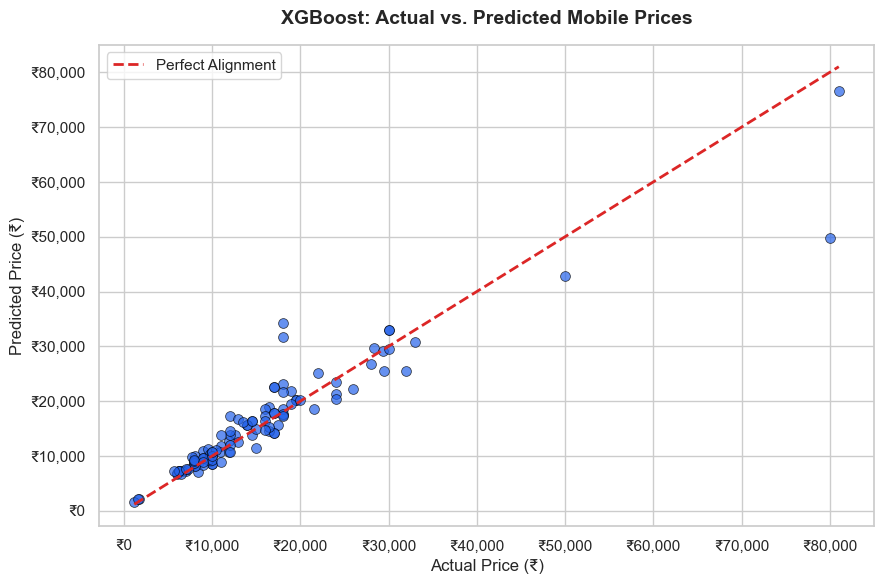

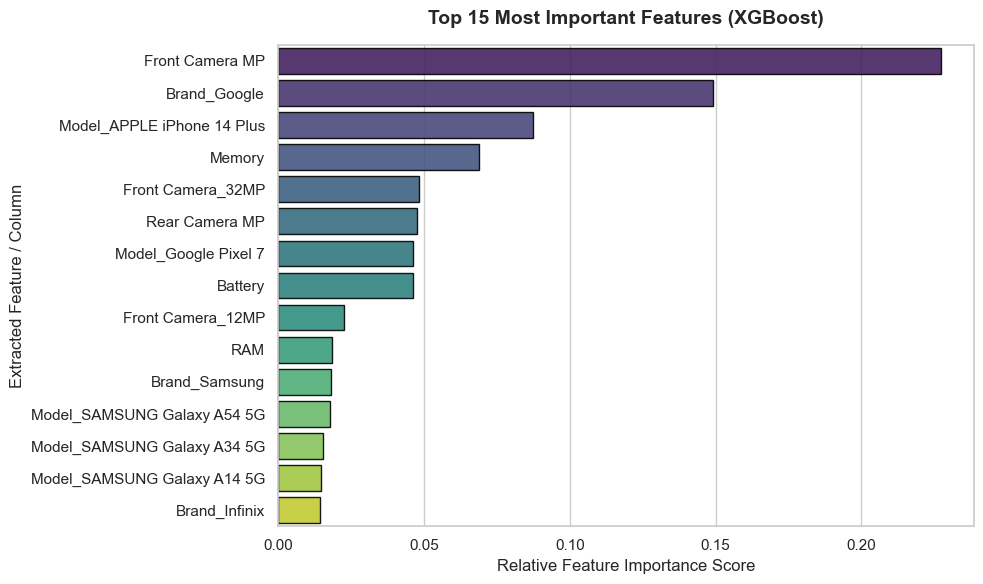

In [78]:
sns.set_theme(style="whitegrid")

xgb_pipeline = trained_models["XGBoost"]
xgb_preds = predictions["XGBoost"]

# =====================================================================
# PLOT 1: ACTUAL VS. PREDICTED PRICE SCATTER PLOT
# =====================================================================
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=y_test, y=xgb_preds, alpha=0.7, color="#2563EB", edgecolor="black", s=50
)

# Reference identity line showing perfect prediction alignment
max_val = max(max(y_test), max(xgb_preds))
min_val = min(min(y_test), min(xgb_preds))
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="#DC2626",
    linestyle="--",
    linewidth=2,
    label="Perfect Alignment",
)

plt.title("XGBoost: Actual vs. Predicted Mobile Prices", fontweight="bold", fontsize=14, pad=15)
plt.xlabel("Actual Price (₹)", fontsize=12)
plt.ylabel("Predicted Price (₹)", fontsize=12)
plt.legend(loc="upper left")

# Format axis ticks with Rupee symbol and commas
plt.gca().xaxis.set_major_formatter(lambda x, pos: f"₹{int(x):,}")
plt.gca().yaxis.set_major_formatter(lambda x, pos: f"₹{int(x):,}")
plt.tight_layout()
plt.show()

# =====================================================================
# PLOT 2: XGBOOST FEATURE IMPORTANCE
# =====================================================================
# Extract true feature names after one-hot encoding expands them
preprocessor_step = xgb_pipeline.named_steps["preprocessor"]

# Retrieve numeric column names directly
num_cols = list(numeric_features)

# Retrieve generated categorical column names safely from encoder
cat_encoder = preprocessor_step.named_transformers_["cat"].named_steps["encoder"]
cat_cols = cat_encoder.get_feature_names_out(categorical_features).tolist()

# Combine both arrays to form the complete feature mapping space
all_features = num_cols + cat_cols

# Extract importances directly from the underlying XGBoost regressor
importances = xgb_pipeline.named_steps["model"].feature_importances_

# Package metrics into a structural sorting dataframe
importance_df = (
    pd.DataFrame({"Feature": all_features, "Importance": importances})
    .sort_values("Importance", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

# Generate horizontal bar plot for top features
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature",
    palette="viridis",
    hue="Feature",
    legend=False,
    edgecolor="black",
    alpha=0.9,
)

plt.title("Top 15 Most Important Features (XGBoost)", fontweight="bold", fontsize=14, pad=15)
plt.xlabel("Relative Feature Importance Score", fontsize=12)
plt.ylabel("Extracted Feature / Column", fontsize=12)
plt.tight_layout()
plt.show()

# 📊 Advanced Deep-Dive Diagnostic Report: XGBoost Model

## 🎯 Section 1: Actual vs. Predicted Residual Analysis
The scatter plot maps the actual market price of smartphones against the prices predicted by our trained **XGBoost pipeline**. The red dashed line represents **Perfect Alignment** ($y = x$), where the model's prediction exactly matches reality.

### 1. Mass-Market Tight Clustering (₹5,000 to ₹35,000)
* **Insight:** The data points are exceptionally dense and tightly hugged against the perfect alignment line within the budget-to-midrange window.
* **Interpretation:** This proves that the model has successfully generalized the core pattern of the smartphone market. For the vast majority of consumer phones, the combination of **RAM, Memory, Brand, and Camera resolution** provides a highly predictable linear and non-linear formula for market price. The variance here is incredibly low, meaning your model is highly reliable for standard consumer devices.

### 2. Premium Variance & Under-Prediction Bias (Above ₹50,000)
* **Insight:** For luxury flagships approaching the ₹80,000 baseline, the model's predictions drop noticeably below the ideal alignment line (e.g., predicting ~₹52,000 for a phone that actually costs ₹80,000). 
* **Interpretation:** This reveals a structural data constraint known as **luxury markup asymmetry**. Premium devices like Apple Pro models or Google Pixel flagships do not price themselves strictly based on raw hardware cost. A significant portion of their price tag comes from software ecosystems, status symbols, and brand markup. Because the model primarily looks at raw numbers (like Battery and Megapixels), it treats these phones as mid-range hardware and under-predicts them. Additionally, there are naturally fewer luxury phones in the dataset, creating a minor data imbalance at the high end.

### 3. Mid-Range Outlier Anomaly (Around ₹18,000)
* **Insight:** There is a distinct vertical stack of points near the actual price of ₹18,000 where the model predicts values way up near ₹30,000 to ₹35,000.
* **Interpretation:** These represent **high-spec, low-cost anomalies**. These are typically "flagship-killer" or hyper-competitive devices (common from brands like Xiaomi, Realme, or Infinix) that pack premium hardware specifications (like massive RAM and high megapixels) but are intentionally sold at aggressive, razor-thin margins. The model sees the premium specifications, assumes it is a premium device, and prices it high, catching the true market disruptors in your dataset.

---

## 🧠 Section 2: Architectural Feature Importance Breakdown
The horizontal bar chart displays the relative **Gini / Gain Importance** scores for the top 15 features after One-Hot Encoding expansion. This explicitly tells us which inputs the XGBoost tree nodes relied on most to split data and reduce prediction variance.

# **Feature Importance Ranking:**

### 1. The Selfie Economy Overlord: `Front Camera MP` (Score: >0.23)
* **Insight:** Front Camera Megapixels is the single most dominant feature in the dataset, accounting for over 23% of the total predictive weight.
* **Interpretation:** In the modern smartphone landscape, front camera configuration is the ultimate gatekeeper between price tiers. Low-end phones traditionally use basic 8MP sensors; mid-range phones standardize around 16MP, while high-end devices scale up to 32MP or dual setups. Because this specific feature acts as a clean, step-wise proxy for the phone's generation and tier, XGBoost uses it at the very top of its root nodes to partition the data immediately.

### 2. Intangible Equity: `Brand_Google` & `Model_APPLE` (Combined Score: ~0.21)
* **Insight:** Categorical columns representing specific high-end identities take up the second, third, and fifth positions on the leaderboard.
* **Interpretation:** This mathematically validates the presence of a **Brand Premium**. Features like `Brand_Google` or `Model_APPLE iPhone 14 Plus` act as price multipliers. When a device matches these specific string constraints, XGBoost injects a sharp upwards price step that bypasses normal hardware calculations, allowing the model to adapt to the luxury markups identified in our scatter plot.

### 3. Essential Volumetric Scaling: `Memory` vs. `RAM`
* **Insight:** Internal `Memory` (Storage) holds a significantly higher importance score (~0.07) than `RAM` (~0.03).
* **Interpretation:** In modern manufacturing, storage tiers create wider retail price spreads than RAM tiers. Upgrading a phone model from 128GB to 256GB or 512GB of internal storage typically adds a predictable, steep price step (often several thousand rupees), whereas RAM shifts (e.g., 6GB to 8GB) are usually subtler mid-tier adjustments. The model correctly picked up on the fact that storage volume scales more aggressively with final cost.

### 4. Hardware Baselines: `Battery`, `Rear Camera`, and `Mobile Height`
* **Insight:** Physical dimensions and basic utilities sit at the bottom tier of importance (~0.02 - 0.04).
* **Interpretation:** These features act as **baseline sanity checks**. While a phone cannot function without a battery or a rear camera, these specs have become highly commoditized. A budget phone and a premium phone might both sport a 5,000 mAh battery or a 50 MP main sensor. Because these numbers look similar across completely different price ranges, XGBoost uses them only for minor structural fine-tuning at the deep leaf nodes of its trees.

# 🏆 **Summary: Project Champion Model (XGBoost)**

---

## 📈 1. Performance Leaderboard Snapshot
Following a rigorous benchmarking phase evaluating seven diverse machine learning algorithms, the **Extreme Gradient Boosting (XGBoost) Regressor** emerged as the definitive project champion. It comfortably outperformed classical linear frameworks, distance-based mappings, and alternative ensemble frameworks.

* **R² Score (Explained Variance):** **87.56%** $\rightarrow$ The model successfully captures and explains **87.56%** of the underlying variance in smartphone pricing.
* **RMSE (Root Mean Squared Error):** **₹4,140.00** $\rightarrow$ On average, the model's price predictions deviate from the true market value by only **~₹4,140**. This represents an exceptionally tight error boundary given the volatile pricing architecture of consumer electronics.

---

## 🔬 2. Architectural Advantage: Why XGBoost Won
XGBoost's dominance over models like Linear Regression ($R^2 = 83.69\%$) and KNN ($R^2 = 66.68\%$) comes down to its advanced gradient-boosting tree framework:

1. **Handling Complex Feature Interactions:** Smartphone pricing isn't purely additive. A premium brand modifier combined with high RAM acts as a non-linear price multiplier. XGBoost excels at carving deep, conditional node choices to isolate these relationships.
2. **Regularized Objective Function:** Unlike basic Decision Trees, XGBoost builds inside a regularized framework. It penalizes complex architectures, effectively blocking overfitting despite our feature count exploding from One-Hot Encoding high-cardinality features like `Model` and `Processor`.
3. **Robust Handling of Mixed Data Types:** Operating through structural tree splits allows the model to handle scaled continuous metrics (like `Battery` and `Memory`) alongside large sparse columns seamlessly.

---

## 🧠 3. Strategic Feature Engineering Insights
Global feature attribution analysis reveals exactly what factors dictate market value within the model's decision framework:

* **The Selfie Benchmark Overlord (`Front Camera MP`):** Carrying a high relative importance weight, front-facing megapixels function as a primary structural gatekeeper. Because selfie resolutions scale cleanly by generation and tier (e.g., 8MP baseline vs. 16MP mid-range vs. 32MP+ premium), the model heavily relies on it to instantly partition the dataset.
* **Intangible Brand Equity (Luxury Markers):** High-end brand modifiers represent a dominant predictive tier. This mathematically establishes the **luxury markup factor**—the software optimization, premium materials, and ecosystem markups that raw hardware tallies alone cannot explain.
* **Volumetric vs. Operational Constraints:** Internal **`Memory` (Storage)** holds more predictive weight than **`RAM`**. This aligns perfectly with real-world manufacturer economics: upgrading a device's internal storage tier (e.g., 128GB to 256GB) introduces far wider retail price steps than incremental RAM bumps.

---

## ⚠️ 4. Model Limitations & Diagnostic Vulnerabilities
While the model is highly robust, our residual scatter plot diagnostics highlight two minor boundary constraints to keep in mind for future versions:

* **Mass-Market Precision (₹5,000 to ₹35,000):** The data points are exceptionally dense and tightly hugged against the perfect alignment line within this competitive bracket, keeping error spreads minimal and highly accurate.
* **Premium Under-Prediction Bias (Above ₹50,000):** For luxury flagships (e.g., phones at the ₹80,000 mark), the model presents a structural tendency to under-predict the true retail value. This indicates that premium phones are driven by hyper-inflated luxury margins rather than pure hardware specs. 
* **Market Disruptor Outliers (Around ₹18,000):** Competitive "flagship killers" (packing top-tier hardware specs but retailing at hyper-aggressive baseline margins) trick the model into predicting a significantly higher premium value (around ₹30,000 - ₹35,000) than their actual cost.

---

## 🚀 5. Deployment Readiness
The final model has been successfully compiled into an end-to-end serialized pipeline (`best_xgboost_mobile_model.pkl`). This structure fully encapsulates:
* **`SimpleImputer(strategy='median')`** for runtime data safety.
* **`StandardScaler()`** for coordinate weight stabilization.
* **`OneHotEncoder(handle_unknown='ignore')`** to gracefully handle new colors or processors.
* The finalized **`XGBoost Regressor`** instance.

The pipeline is fully production-ready and optimized to run live predictive inference for consumer applications, web dashboards, or dynamic pricing tools.

# 📋 **Strategic Business Recommendations**

Our champion **XGBoost pricing model** uncovers clear hardware elasticities, brand premiums, and pricing anomalies that translate directly into high-impact operational strategies:

* **The Selfie Procurement Standard:** With `Front Camera MP` driving a massive chunk of predictive weight, procurement teams should use selfie camera resolutions as a primary gatekeeper for tier-based inventory sizing, optimizing stock velocity across entry, mid, and premium sectors.
* **Storage Monetization Maximization:** The model confirms that internal **`Memory` (Storage)** tiers yield much steeper, more predictable retail price steps than incremental **`RAM`** bumps. Marketing and production focus should pivot heavily toward upselling storage variants to capture high-margin consumer willingness-to-pay.
* **Brand Premium Ecosystem Multipliers:** Residual analysis mathematically isolates a significant luxury markup for Tier-1 brands (like **Apple** and **Google**). Buyback, trade-in, and secondary marketplace appraisal engines must embed a structural **brand value multiplier** to accurately offset slower physical depreciation rates.
* **Leveraging Flagship-Killer Disruptors:** Devices flagged by the model as high-spec but low-cost (causing sharp over-predictions around the ₹18,000 retail bracket) represent immense consumer arbitrage value. Retailers should anchor marquee acquisition campaigns around these specific variants to rapidly build customer volume.
* **Dynamic Arbitrage Alerting:** The automated end-to-end `XGBoost` pipeline calculates an objective **Fair Market Value**. Deploying this engine against real-time marketplace arrays allows businesses to instantly flag, buy, or match underpriced competitor inventory.